# Chronic-Disease Burden in US Counties (spoke-okn CDC PLACES + County Health Rankings)

- **Date:** 2026-11-18
- **Model:** claude-opus-5-5
- **Skills:** okn-bioanalysis v0.1.3 · okn-report-style v0.2.1
- **External MCP servers:** PubMed · Paperclip
- **SPARQL endpoint:** https://apps.okn.us/federation/sparql
- **Generated by:** mcp-okn v0.6.3 (build c09ddbd)
- **Queries:** 20
- **Study active window:** 2026-11-19 03:01–04:46 UTC (1h 44m)
- **Knowledge graphs used:** `spoke-okn`, `ubergraph`

## Prompt

Identify US counties with high prevalence of common chronic diseases, including diabetes, obesity, asthma, COPD, cardiovascular disease, hypertension, and other conditions supported by available knowledge graphs.
1. Discover data: Identify relevant knowledge graphs, retrieve county-level disease prevalence estimates, and document data sources, years, and coverage.
2. Analyze prevalence: Identify counties with the highest prevalence of individual diseases and those with high prevalence across multiple conditions. Develop a composite disease-burden score.
3. Create interactive maps: Visualize county-level disease prevalence and composite disease burden, with options to select different diseases.
4. Analyze correlations: Create a clustered correlation heatmap across diseases. Identify notable associations and consider potential demographic or geographic confounders.
5. Ensure reproducibility: Generate a complete, executable Jupyter Notebook containing the queries, data processing, analyses, visualizations, and key findings.
Use appropriate statistical methods, validate the data, and clearly document assumptions and limitations. Prioritize data available through mcp-okn and identify any gaps.
Use the /okn-bioanalysis and /okn-report-style skills.

## Notes

County prevalence = population-weighted mean of CDC PLACES place-level age-adjusted crude-model estimates (spoke-okn PREVALENCE_DpL, place→county via PARTOF_LpL), computed server-side in five state-FIPS shards. County Health Rankings 2023 (spoke-okn PREVALENCEIN_SpL) supplies an independent diabetes/obesity validation and 10 demographic/behavioural covariates. Composite = mean z of 9 conditions; Spearman correlations clustered on 1−ρ, adjusted by rank-residual partial correlation and state demeaning; Moran's I / LISA (KNN k=6); disease–gene overlap from spoke-okn ASSOCIATES_DaG with DOID→MONDO via ubergraph. Ecological, observational, model-based small-area estimates — not individual-level or causal.

## Re-running this study

Every query cell loads the rows the session logged (`data/`), so the notebook runs offline and shows the original results. Set `RERUN = True` in the next cell (or start Jupyter with `OKN_RERUN=1`) to re-execute every query live against the OKN federation instead, or run the last cell (`verify_all()`) to compare each query's live row count with the logged one. A changed count usually means the knowledge graph was redeployed since the study ran, not that the analysis is wrong.

In [1]:
import os

import pandas as pd

from okn_sparql import run_query, verify_all

# False: load the rows logged during the session (data/). True: re-run each query live.
# Starting Jupyter with OKN_RERUN=1 sets it without editing the notebook.
RERUN = os.environ.get("OKN_RERUN", "") == "1"
data: dict[str, pd.DataFrame] = {}

## SPARQL queries

### q01 — Inventory: PREVALENCE_DpL statements by disease, source, year and value type

2026-11-19T03:01:55+00:00 · `spoke-okn` · 153 rows logged

<details><summary>SPARQL (13 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
SELECT ?disease ?dlabel ?source ?year ?dvt (COUNT(?stmt) AS ?n) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:subject ?disease ; rdf:predicate kg:PREVALENCE_DpL ; rdf:object ?loc .
    OPTIONAL { ?stmt dcterms:source ?source }
    OPTIONAL { ?stmt kg:year ?year }
    OPTIONAL { ?stmt kg:data_value_type ?dvt }
    OPTIONAL { ?disease rdfs:label ?dlabel }
  }
} GROUP BY ?disease ?dlabel ?source ?year ?dvt</code></pre>
</details>

In [2]:
data["q01"] = run_query("q01", rerun=RERUN)
data["q01"].head(10)

,disease,dlabel,source,year,dvt,n
0,http://purl.obolibrary.org/obo/DOID_0050567,orofacial cleft,IHME,2019.0,NaN,200
1,http://purl.obolibrary.org/obo/DOID_0050589,inflammatory bowel disease,IHME,2019.0,NaN,200
2,http://purl.obolibrary.org/obo/DOID_0050700,cardiomyopathy,IHME,2019.0,NaN,200
3,http://purl.obolibrary.org/obo/DOID_0050827,rheumatic heart disease,IHME,2019.0,NaN,200
4,http://purl.obolibrary.org/obo/DOID_0050830,peripheral artery disease,IHME,2019.0,NaN,200
5,http://purl.obolibrary.org/obo/DOID_0060041,autism spectrum disorder,IHME,2019.0,NaN,200
6,http://purl.obolibrary.org/obo/DOID_0060060,non-Hodgkin lymphoma,IHME,2019.0,NaN,200
7,http://purl.obolibrary.org/obo/DOID_0060262,gallbladder disease,IHME,2019.0,NaN,200
8,http://purl.obolibrary.org/obo/DOID_0060329,ectopic pregnancy,IHME,2019.0,NaN,200
9,http://purl.obolibrary.org/obo/DOID_0060478,Zika fever,IHME,2019.0,NaN,200


### q02 — Inventory: location kinds carrying diabetes prevalence (place vs county)

2026-11-19T03:02:05+00:00 · `spoke-okn` · 1 row logged

<details><summary>SPARQL (10 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
SELECT ?kind (COUNT(?stmt) AS ?n) (COUNT(DISTINCT ?loc) AS ?nloc) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:subject &lt;http://purl.obolibrary.org/obo/DOID_9351&gt; ; rdf:predicate kg:PREVALENCE_DpL ; rdf:object ?loc ;
          dcterms:source "PLACES" .
    OPTIONAL { ?loc &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; ?kind }
  }
} GROUP BY ?kind</code></pre>
</details>

Runs as `queries/sent/q02.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [3]:
data["q02"] = run_query("q02", rerun=RERUN)
data["q02"].head(10)

,kind,n,nloc
0,https://schema.org/City,27365,27365


### q03 — Inventory: CDC PLACES measures, value completeness and ranges per disease

2026-11-19T03:02:31+00:00 · `spoke-okn` · 9 rows logged

<details><summary>SPARQL (12 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
SELECT ?disease ?sqt (COUNT(?stmt) AS ?n) (COUNT(?dv) AS ?n_value) (COUNT(?lo) AS ?n_lower) (COUNT(?pop) AS ?n_pop) (MIN(?dv) AS ?min) (MAX(?dv) AS ?max) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?disease ; dcterms:source "PLACES" .
    OPTIONAL { ?stmt kg:short_question_text ?sqt }
    OPTIONAL { ?stmt kg:data_value ?dv }
    OPTIONAL { ?stmt kg:lower ?lo }
    OPTIONAL { ?stmt kg:total_population ?pop }
  }
} GROUP BY ?disease ?sqt</code></pre>
</details>

In [4]:
data["q03"] = run_query("q03", rerun=RERUN)
data["q03"].head(10)

,disease,sqt,n,n_value,n_lower,n_pop,min,max
0,http://purl.obolibrary.org/obo/DOID_10763,High Blood Pressure,27365,26343,0,27365,NaN,57.5
1,http://purl.obolibrary.org/obo/DOID_1596,Depression,27365,26343,0,27365,NaN,35.4
2,http://purl.obolibrary.org/obo/DOID_2349,High Cholesterol,27365,26343,0,27365,NaN,39.3
3,http://purl.obolibrary.org/obo/DOID_2841,Current Asthma,27365,26343,0,27365,NaN,18.5
4,http://purl.obolibrary.org/obo/DOID_3083,COPD,27365,26343,0,27365,NaN,20.2
5,http://purl.obolibrary.org/obo/DOID_3393,Coronary Heart Disease,27365,26343,0,27365,NaN,13.7
6,http://purl.obolibrary.org/obo/DOID_6713,Stroke,27365,26343,0,27365,NaN,8.8
7,http://purl.obolibrary.org/obo/DOID_9351,Diabetes,27365,26343,0,27365,NaN,27.1
8,http://purl.obolibrary.org/obo/DOID_9970,Obesity,27365,26343,0,27365,NaN,60.4


### q04 — Inventory: PREVALENCEIN_SpL (SDoH) statements by source, year and method

2026-11-19T03:03:08+00:00 · `spoke-okn` · 19 rows logged

<details><summary>SPARQL (10 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
SELECT ?source ?year ?method (COUNT(?stmt) AS ?n) (COUNT(DISTINCT ?sdoh) AS ?nsdoh) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?sdoh ; rdf:object ?loc .
    ?loc &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; .
    OPTIONAL { ?stmt dcterms:source ?source } OPTIONAL { ?stmt kg:year ?year } OPTIONAL { ?stmt kg:method ?method }
  }
} GROUP BY ?source ?year ?method</code></pre>
</details>

Runs as `queries/sent/q04.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [5]:
data["q04"] = run_query("q04", rerun=RERUN)
data["q04"].head(10)

,source,year,method,n,nsdoh
0,AHRQ SDOH Database,2010,NaN,109512,72
1,AHRQ SDOH Database,2012,NaN,11645,4
2,AHRQ SDOH Database,2014,NaN,12594,4
3,AHRQ SDOH Database,2015,NaN,164463,88
4,AHRQ SDOH Database,2016,NaN,16990,6
5,AHRQ SDOH Database,2017,NaN,37395,12
6,AHRQ SDOH Database,2018,NaN,478775,203
7,AHRQ SDOH Database,2019,NaN,399424,144
8,AHRQ SDOH Database,2020,NaN,1525901,528
9,County Health Rankings,2023,average,14578,5


### q05 — Inventory: County Health Rankings variables available as county-native measures

2026-11-19T03:03:19+00:00 · `spoke-okn` · 82 rows logged

<details><summary>SPARQL (11 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
SELECT ?sdoh ?label ?method ?variable (COUNT(?stmt) AS ?n) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?sdoh ; rdf:object ?loc ; dcterms:source "County Health Rankings" .
    ?loc &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; .
    OPTIONAL { ?stmt kg:method ?method } OPTIONAL { ?stmt kg:variable ?variable } OPTIONAL { ?sdoh rdfs:label ?label }
  }
} GROUP BY ?sdoh ?label ?method ?variable</code></pre>
</details>

Runs as `queries/sent/q05.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [6]:
data["q05"] = run_query("q05", rerun=RERUN)
data["q05"].head(10)

,sdoh,label,method,variable,n
0,https://purl.org/okn/frink/kg/spoke-okn/sdoh/1...,Access to physical activity facility (observab...,percentage(quartile),access to exercise opportunities,3069
1,https://purl.org/okn/frink/kg/spoke-okn/sdoh/8...,Administration of vaccine product containing o...,percentage(quartile),flu vaccinations,3114
2,https://purl.org/okn/frink/kg/spoke-okn/sdoh/1...,Air pollution (event),average(quartile),air pollution - particulate matter,3107
3,https://purl.org/okn/frink/kg/spoke-okn/sdoh/C...,alcohol-impaired_driving_deaths,percentage(quartile),alcohol-impaired driving deaths,3105
4,https://purl.org/okn/frink/kg/spoke-okn/sdoh/4...,American Indian or Alaska native (racial group),percentage,american indian or alaska native,3131
5,https://purl.org/okn/frink/kg/spoke-okn/sdoh/4...,Asian race (racial group),percentage,asian,3131
6,https://purl.org/okn/frink/kg/spoke-okn/sdoh/C...,broadband_access,percentage,broadband access,3131
7,https://purl.org/okn/frink/kg/spoke-okn/sdoh/C...,census_participation,percentage,census participation,3129
8,https://purl.org/okn/frink/kg/spoke-okn/sdoh/4...,Child day care center (environment),percentage,child care centers,2984
9,https://purl.org/okn/frink/kg/spoke-okn/sdoh/C...,child_care_cost_burden,percentage,child care cost burden,3130


### q06 — Join check: number of counties each PLACES place links to via PARTOF_LpL

2026-11-19T03:03:20+00:00 · `spoke-okn` · 2 rows logged

<details><summary>SPARQL (8 lines)</summary>
<pre><code class="language-sparql">PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
SELECT ?ncounty (COUNT(?city) AS ?nplaces) WHERE {
  { SELECT ?city (COUNT(DISTINCT ?county) AS ?ncounty) WHERE {
    GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
      &lt;http://purl.obolibrary.org/obo/DOID_9351&gt; kg:PREVALENCE_DpL ?city .
      OPTIONAL { ?city kg:PARTOF_LpL ?county . ?county &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; . }
    } } GROUP BY ?city }
} GROUP BY ?ncounty</code></pre>
</details>

In [7]:
data["q06"] = run_query("q06", rerun=RERUN)
data["q06"].head(10)

,ncounty,nplaces
0,0,1407
1,1,26158


### q07 — Pilot: population-weighted county diabetes prevalence (single-disease aggregation test)

2026-11-19T03:04:45+00:00 · `spoke-okn` · 3,057 rows logged

<details><summary>SPARQL (11 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
SELECT ?fips (SUM(?dv * ?pop) AS ?wsum) (SUM(?pop) AS ?popsum) (COUNT(?city) AS ?nplaces) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:subject &lt;http://purl.obolibrary.org/obo/DOID_9351&gt; ; rdf:predicate kg:PREVALENCE_DpL ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?county . ?county &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; .
    BIND(REPLACE(STR(?county), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips</code></pre>
</details>

In [8]:
data["q07"] = run_query("q07", rerun=RERUN)
data["q07"].head(10)

,fips,wsum,popsum,nplaces
0,1001,67948.6,6615,4
1,1003,966767.0,98544,15
2,1005,293050.0,18438,6
3,1007,121432.0,8965,3
4,1009,185042.0,16979,12
5,1011,86348.0,4562,3
6,1013,152551.0,9873,2
7,1015,823150.0,63128,11
8,1017,306507.0,22593,10
9,1019,77722.6,6914,6


### q08 — PLACES 9-condition county table, state FIPS 01-12

2026-11-19T03:05:44+00:00 · `spoke-okn` · 320 rows logged

<details><summary>SPARQL (16 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# CDC PLACES place-level age-adjusted prevalence (spoke-okn PREVALENCE_DpL) -&gt; population-weighted county mean via PARTOF_LpL; state FIPS 01-12
SELECT ?fips ?county (ROUND(10*SUM(IF(?d = obo:DOID_9351, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9351, ?pop, 0)))/10 AS ?diabetes) (ROUND(10*SUM(IF(?d = obo:DOID_9970, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9970, ?pop, 0)))/10 AS ?obesity) (ROUND(10*SUM(IF(?d = obo:DOID_10763, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_10763, ?pop, 0)))/10 AS ?hypertension) (ROUND(10*SUM(IF(?d = obo:DOID_2349, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2349, ?pop, 0)))/10 AS ?high_chol) (ROUND(10*SUM(IF(?d = obo:DOID_3393, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3393, ?pop, 0)))/10 AS ?chd) (ROUND(10*SUM(IF(?d = obo:DOID_6713, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_6713, ?pop, 0)))/10 AS ?stroke) (ROUND(10*SUM(IF(?d = obo:DOID_3083, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3083, ?pop, 0)))/10 AS ?copd) (ROUND(10*SUM(IF(?d = obo:DOID_2841, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2841, ?pop, 0)))/10 AS ?asthma) (ROUND(10*SUM(IF(?d = obo:DOID_1596, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_1596, ?pop, 0)))/10 AS ?depression) (SUM(IF(?d = obo:DOID_9351, ?pop, 0)) AS ?pop_places) (SUM(IF(?d = obo:DOID_9351, 1, 0)) AS ?n_places) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?d ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ;
          kg:state_fips ?sf ; rdfs:label ?county .
    FILTER(?sf &gt;= "01" &amp;&amp; ?sf &lt;= "12")
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips ?county</code></pre>
</details>

Runs as `queries/sent/q08.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [9]:
data["q08"] = run_query("q08", rerun=RERUN)
data["q08"].head(10)

,fips,county,diabetes,obesity,hypertension,high_chol,chd,stroke,copd,asthma,depression,pop_places,n_places
0,8001,Adams County,9.8,33.2,26.6,26.3,5.6,3.1,6.7,11.2,22.1,124899,10
1,6001,Alameda County,9.3,26.2,25.8,30.6,4.2,2.5,4.0,9.1,17.0,1502049,20
2,8003,Alamosa County,11.8,31.7,28.6,29.4,6.0,3.3,6.9,11.3,22.6,10367,3
3,2013,Aleutians East Borough,12.7,31.8,32.0,30.3,6.5,3.6,5.8,8.1,14.0,2941,3
4,2016,Aleutians West Census Area,10.8,31.7,29.6,30.2,5.6,3.1,5.1,7.9,14.7,5018,4
5,6003,Alpine County,9.2,30.0,28.2,30.6,5.8,3.0,6.8,10.6,22.8,645,4
6,6005,Amador County,8.7,29.7,27.4,30.9,5.3,2.7,6.1,9.8,20.4,26771,16
7,2020,Anchorage Municipality,7.6,32.9,27.4,28.8,4.7,2.6,5.3,9.5,20.1,291826,1
8,4001,Apache County,14.8,37.0,32.1,29.6,8.0,5.1,10.2,13.4,19.4,39221,31
9,8005,Arapahoe County,6.0,23.2,23.5,28.7,3.8,2.1,4.4,10.2,20.3,185692,17


### q09 — Coverage: PLACES places and linked counties per state

2026-11-19T04:43:19+00:00 · `spoke-okn` · 50 rows logged

<details><summary>SPARQL (9 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
SELECT ?state (COUNT(DISTINCT ?city) AS ?places) (COUNT(DISTINCT ?c) AS ?counties_linked) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject &lt;http://purl.obolibrary.org/obo/DOID_9351&gt; ; rdf:object ?city ; dcterms:source "PLACES" ; kg:state_abbr ?state .
    OPTIONAL { ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; . }
  }
} GROUP BY ?state</code></pre>
</details>

In [10]:
data["q09"] = run_query("q09", rerun=RERUN)
data["q09"].head(10)

,state,places,counties_linked
0,AK,292,29
1,AL,567,67
2,AR,533,75
3,AZ,414,15
4,CA,1458,58
5,CO,429,64
6,CT,140,8
7,DC,1,1
8,DE,76,3
9,GA,615,156


### q10 — PLACES 9-condition county table, state FIPS 13-19

2026-11-19T04:43:48+00:00 · `spoke-okn` · 497 rows logged

<details><summary>SPARQL (16 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# CDC PLACES place-level age-adjusted prevalence (spoke-okn PREVALENCE_DpL) -&gt; population-weighted county mean via PARTOF_LpL; state FIPS 13-19
SELECT ?fips ?county (ROUND(10*SUM(IF(?d = obo:DOID_9351, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9351, ?pop, 0)))/10 AS ?diabetes) (ROUND(10*SUM(IF(?d = obo:DOID_9970, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9970, ?pop, 0)))/10 AS ?obesity) (ROUND(10*SUM(IF(?d = obo:DOID_10763, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_10763, ?pop, 0)))/10 AS ?hypertension) (ROUND(10*SUM(IF(?d = obo:DOID_2349, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2349, ?pop, 0)))/10 AS ?high_chol) (ROUND(10*SUM(IF(?d = obo:DOID_3393, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3393, ?pop, 0)))/10 AS ?chd) (ROUND(10*SUM(IF(?d = obo:DOID_6713, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_6713, ?pop, 0)))/10 AS ?stroke) (ROUND(10*SUM(IF(?d = obo:DOID_3083, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3083, ?pop, 0)))/10 AS ?copd) (ROUND(10*SUM(IF(?d = obo:DOID_2841, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2841, ?pop, 0)))/10 AS ?asthma) (ROUND(10*SUM(IF(?d = obo:DOID_1596, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_1596, ?pop, 0)))/10 AS ?depression) (SUM(IF(?d = obo:DOID_9351, ?pop, 0)) AS ?pop_places) (SUM(IF(?d = obo:DOID_9351, 1, 0)) AS ?n_places) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?d ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ;
          kg:state_fips ?sf ; rdfs:label ?county .
    FILTER(?sf &gt;= "13" &amp;&amp; ?sf &lt;= "19")
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips ?county</code></pre>
</details>

Runs as `queries/sent/q10.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [11]:
data["q10"] = run_query("q10", rerun=RERUN)
data["q10"].head(10)

,fips,county,diabetes,obesity,hypertension,high_chol,chd,stroke,copd,asthma,depression,pop_places,n_places
0,16001,Ada County,7.9,28.8,26.2,26.7,4.9,2.5,5.0,9.8,25.8,335567,6
1,19001,Adair County,8.6,37.7,27.7,28.9,5.2,2.7,6.8,9.6,18.8,3244,4
2,16003,Adams County,8.7,30.6,28.8,27.8,5.6,2.8,6.3,10.4,23.7,1335,2
3,17001,Adams County,9.5,37.0,31.5,28.8,5.6,2.9,7.3,10.4,23.2,47278,13
4,18001,Adams County,11.3,39.3,32.9,30.9,6.3,3.2,9.0,11.1,27.3,15588,4
5,19003,Adams County,8.5,38.0,28.9,29.8,5.2,2.7,6.8,9.7,19.2,2006,3
6,17003,Alexander County,13.2,43.9,37.3,29.3,6.4,3.9,8.6,11.8,21.3,5550,6
7,19005,Allamakee County,8.3,35.3,27.1,30.2,5.2,2.7,6.6,9.5,18.7,5890,5
8,18003,Allen County,11.8,39.6,33.7,30.6,6.0,3.2,7.7,11.5,23.6,285078,9
9,19007,Appanoose County,9.7,38.9,30.2,30.5,5.7,3.0,7.8,10.4,21.2,7318,7


### q11 — PLACES 9-condition county table, state FIPS 20-29

2026-11-19T04:44:04+00:00 · `spoke-okn` · 710 rows logged

<details><summary>SPARQL (16 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# CDC PLACES place-level age-adjusted prevalence (spoke-okn PREVALENCE_DpL) -&gt; population-weighted county mean via PARTOF_LpL; state FIPS 20-29
SELECT ?fips ?county (ROUND(10*SUM(IF(?d = obo:DOID_9351, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9351, ?pop, 0)))/10 AS ?diabetes) (ROUND(10*SUM(IF(?d = obo:DOID_9970, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9970, ?pop, 0)))/10 AS ?obesity) (ROUND(10*SUM(IF(?d = obo:DOID_10763, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_10763, ?pop, 0)))/10 AS ?hypertension) (ROUND(10*SUM(IF(?d = obo:DOID_2349, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2349, ?pop, 0)))/10 AS ?high_chol) (ROUND(10*SUM(IF(?d = obo:DOID_3393, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3393, ?pop, 0)))/10 AS ?chd) (ROUND(10*SUM(IF(?d = obo:DOID_6713, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_6713, ?pop, 0)))/10 AS ?stroke) (ROUND(10*SUM(IF(?d = obo:DOID_3083, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3083, ?pop, 0)))/10 AS ?copd) (ROUND(10*SUM(IF(?d = obo:DOID_2841, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2841, ?pop, 0)))/10 AS ?asthma) (ROUND(10*SUM(IF(?d = obo:DOID_1596, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_1596, ?pop, 0)))/10 AS ?depression) (SUM(IF(?d = obo:DOID_9351, ?pop, 0)) AS ?pop_places) (SUM(IF(?d = obo:DOID_9351, 1, 0)) AS ?n_places) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?d ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ;
          kg:state_fips ?sf ; rdfs:label ?county .
    FILTER(?sf &gt;= "20" &amp;&amp; ?sf &lt;= "29")
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips ?county</code></pre>
</details>

Runs as `queries/sent/q11.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [12]:
data["q11"] = run_query("q11", rerun=RERUN)
data["q11"].head(10)

,fips,county,diabetes,obesity,hypertension,high_chol,chd,stroke,copd,asthma,depression,pop_places,n_places
0,22001,Acadia Parish,14.6,42.3,41.7,34.2,7.4,4.3,11.0,11.7,30.7,30659,9
1,21001,Adair County,11.9,41.4,37.7,32.8,6.8,3.5,10.4,12.1,29.0,4452,1
2,29001,Adair County,10.6,38.0,32.6,32.5,6.5,3.2,9.0,10.6,27.6,18323,4
3,28001,Adams County,16.1,45.0,44.6,31.7,7.1,4.5,9.0,11.8,21.6,18118,3
4,27001,Aitkin County,9.4,38.5,29.3,28.1,5.7,3.0,6.6,10.3,25.7,3515,6
5,26001,Alcona County,8.5,34.7,29.6,31.1,5.6,2.8,7.0,11.0,26.1,2144,4
6,28003,Alcorn County,11.6,39.1,38.1,31.9,6.4,3.5,8.2,10.5,23.8,17697,5
7,26003,Alger County,8.9,34.9,30.4,31.0,5.9,3.0,7.5,11.2,26.0,2575,2
8,26005,Allegan County,8.9,38.8,30.8,32.1,5.5,2.8,7.1,11.4,24.5,21415,9
9,24001,Allegany County,10.6,41.9,34.8,32.4,5.8,3.1,7.4,10.6,24.9,55433,39


### q12 — PLACES 9-condition county table, state FIPS 30-41

2026-11-19T04:44:18+00:00 · `spoke-okn` · 639 rows logged

<details><summary>SPARQL (16 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# CDC PLACES place-level age-adjusted prevalence (spoke-okn PREVALENCE_DpL) -&gt; population-weighted county mean via PARTOF_LpL; state FIPS 30-41
SELECT ?fips ?county (ROUND(10*SUM(IF(?d = obo:DOID_9351, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9351, ?pop, 0)))/10 AS ?diabetes) (ROUND(10*SUM(IF(?d = obo:DOID_9970, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9970, ?pop, 0)))/10 AS ?obesity) (ROUND(10*SUM(IF(?d = obo:DOID_10763, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_10763, ?pop, 0)))/10 AS ?hypertension) (ROUND(10*SUM(IF(?d = obo:DOID_2349, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2349, ?pop, 0)))/10 AS ?high_chol) (ROUND(10*SUM(IF(?d = obo:DOID_3393, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3393, ?pop, 0)))/10 AS ?chd) (ROUND(10*SUM(IF(?d = obo:DOID_6713, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_6713, ?pop, 0)))/10 AS ?stroke) (ROUND(10*SUM(IF(?d = obo:DOID_3083, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3083, ?pop, 0)))/10 AS ?copd) (ROUND(10*SUM(IF(?d = obo:DOID_2841, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2841, ?pop, 0)))/10 AS ?asthma) (ROUND(10*SUM(IF(?d = obo:DOID_1596, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_1596, ?pop, 0)))/10 AS ?depression) (SUM(IF(?d = obo:DOID_9351, ?pop, 0)) AS ?pop_places) (SUM(IF(?d = obo:DOID_9351, 1, 0)) AS ?n_places) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?d ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ;
          kg:state_fips ?sf ; rdfs:label ?county .
    FILTER(?sf &gt;= "30" &amp;&amp; ?sf &lt;= "41")
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips ?county</code></pre>
</details>

Runs as `queries/sent/q12.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [13]:
data["q12"] = run_query("q12", rerun=RERUN)
data["q12"].head(10)

,fips,county,diabetes,obesity,hypertension,high_chol,chd,stroke,copd,asthma,depression,pop_places,n_places
0,40001,Adair County,16.0,43.7,41.0,32.1,8.6,4.6,11.4,13.6,27.2,11906,22
1,31001,Adams County,9.4,38.0,31.9,29.7,5.3,2.8,6.2,9.0,20.5,27319,5
2,38001,Adams County,8.1,39.3,28.8,28.3,5.0,2.5,5.4,9.3,19.8,1388,2
3,39001,Adams County,13.0,42.9,36.1,32.3,7.6,3.7,11.6,11.8,26.9,9577,8
4,37001,Alamance County,11.2,37.2,32.8,32.3,6.0,3.3,7.4,10.4,25.2,36278,11
5,36001,Albany County,11.2,35.4,32.2,30.8,5.6,3.0,7.2,12.2,24.7,154112,11
6,37003,Alexander County,9.5,34.7,30.7,31.8,5.8,3.0,7.3,9.9,25.2,6853,3
7,40003,Alfalfa County,9.9,37.2,35.1,31.4,6.0,3.0,6.9,10.3,23.4,4077,7
8,36003,Allegany County,10.2,36.5,30.5,31.9,5.8,2.8,7.8,11.7,25.0,21476,16
9,37005,Alleghany County,12.7,39.1,35.2,33.4,7.2,3.7,10.0,10.7,26.7,1770,1


### q13 — PLACES 9-condition county table, state FIPS 42-56

2026-11-19T04:44:32+00:00 · `spoke-okn` · 891 rows logged

<details><summary>SPARQL (16 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# CDC PLACES place-level age-adjusted prevalence (spoke-okn PREVALENCE_DpL) -&gt; population-weighted county mean via PARTOF_LpL; state FIPS 42-56
SELECT ?fips ?county (ROUND(10*SUM(IF(?d = obo:DOID_9351, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9351, ?pop, 0)))/10 AS ?diabetes) (ROUND(10*SUM(IF(?d = obo:DOID_9970, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_9970, ?pop, 0)))/10 AS ?obesity) (ROUND(10*SUM(IF(?d = obo:DOID_10763, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_10763, ?pop, 0)))/10 AS ?hypertension) (ROUND(10*SUM(IF(?d = obo:DOID_2349, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2349, ?pop, 0)))/10 AS ?high_chol) (ROUND(10*SUM(IF(?d = obo:DOID_3393, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3393, ?pop, 0)))/10 AS ?chd) (ROUND(10*SUM(IF(?d = obo:DOID_6713, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_6713, ?pop, 0)))/10 AS ?stroke) (ROUND(10*SUM(IF(?d = obo:DOID_3083, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_3083, ?pop, 0)))/10 AS ?copd) (ROUND(10*SUM(IF(?d = obo:DOID_2841, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_2841, ?pop, 0)))/10 AS ?asthma) (ROUND(10*SUM(IF(?d = obo:DOID_1596, ?dv*?pop, 0))/SUM(IF(?d = obo:DOID_1596, ?pop, 0)))/10 AS ?depression) (SUM(IF(?d = obo:DOID_9351, ?pop, 0)) AS ?pop_places) (SUM(IF(?d = obo:DOID_9351, 1, 0)) AS ?n_places) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    ?stmt rdf:predicate kg:PREVALENCE_DpL ; rdf:subject ?d ; rdf:object ?city ;
          dcterms:source "PLACES" ; kg:data_value ?dv ; kg:total_population ?pop .
    ?city kg:PARTOF_LpL ?c . ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ;
          kg:state_fips ?sf ; rdfs:label ?county .
    FILTER(?sf &gt;= "42" &amp;&amp; ?sf &lt;= "56")
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips ?county</code></pre>
</details>

Runs as `queries/sent/q13.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [14]:
data["q13"] = run_query("q13", rerun=RERUN)
data["q13"].head(10)

,fips,county,diabetes,obesity,hypertension,high_chol,chd,stroke,copd,asthma,depression,pop_places,n_places
0,45001,Abbeville County,12.9,41.7,38.1,31.2,6.2,3.7,7.9,10.8,23.1,10229,7
1,51001,Accomack County,12.3,39.8,36.6,33.0,6.0,3.6,8.2,11.6,22.4,19849,44
2,42001,Adams County,8.9,37.7,30.0,30.5,5.5,2.7,6.6,10.7,23.9,39635,26
3,53001,Adams County,12.3,38.6,30.6,28.9,6.3,3.6,7.5,11.9,23.5,9816,4
4,55001,Adams County,8.6,37.5,29.0,31.7,5.7,2.9,6.7,11.0,24.3,5576,8
5,50001,Addison County,6.9,29.6,24.0,27.4,4.6,2.4,5.5,10.4,26.3,11631,4
6,45003,Aiken County,12.1,37.8,35.7,33.8,5.8,3.2,7.4,10.0,21.8,55917,14
7,56001,Albany County,8.8,29.5,26.7,29.3,5.3,2.7,6.3,10.0,22.2,31334,3
8,51003,Albemarle County,8.8,28.2,28.9,32.5,4.5,2.4,5.1,9.6,22.9,25575,8
9,51510,Alexandria city,8.9,30.6,29.7,31.0,4.2,2.4,4.4,9.9,18.7,139966,1


### q14 — County Health Rankings 2023 covariates + validation measures, state FIPS 49-56

2026-11-19T04:45:13+00:00 · `spoke-okn` · 362 rows logged

<details><summary>SPARQL (15 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX xsd: &lt;http://www.w3.org/2001/XMLSchema#&gt;
# County Health Rankings 2023 county-native measures (spoke-okn PREVALENCEIN_SpL), one row per county; value parsed from "v(quartile)"; -999 = missing; state FIPS 49-56
SELECT ?fips (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt;, ?x, -999)) AS ?chr_diabetes) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt;, ?x, -999)) AS ?chr_obesity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt;, ?x, -999)) AS ?smoking) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt;, ?x, -999)) AS ?inactivity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt;, ?x, -999)) AS ?age65) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt;, ?x, -999)) AS ?nh_black) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt;, ?x, -999)) AS ?hispanic) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt;, ?x, -999)) AS ?rural) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt;, ?x, -999)) AS ?child_poverty) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt;, ?x, -999)) AS ?uninsured) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt;, ?x, -999)) AS ?some_college) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt;, ?x, -999)) AS ?food_insec) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt;, ?x, -999)) AS ?phys_distress) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt;, ?x, -999)) AS ?life_exp) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?s { &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt; }
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?s ; rdf:object ?c ; dcterms:source "County Health Rankings" ; kg:value ?v .
    ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ; kg:state_fips ?sf .
    FILTER(?sf &gt;= "49" &amp;&amp; ?sf &lt;= "56")
    BIND(ROUND(10*xsd:decimal(STRBEFORE(CONCAT(STR(?v), "("), "(")))/10 AS ?x)
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips</code></pre>
</details>

Runs as `queries/sent/q14.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [15]:
data["q14"] = run_query("q14", rerun=RERUN)
data["q14"].head(10)

,fips,chr_diabetes,chr_obesity,smoking,inactivity,age65,nh_black,hispanic,rural,child_poverty,uninsured,some_college,food_insec,phys_distress,life_exp
0,49001,8.3,27.8,9.9,16.4,15.5,0.3,12.7,56.5,13.0,15.3,68.4,8.1,8.9,78.5
1,49003,8.7,32.6,10.5,18.2,12.9,0.4,9.8,31.1,8.1,10.7,62.7,9.9,9.7,78.8
2,49005,9.8,29.6,9.2,16.7,9.9,0.9,11.2,15.7,9.0,11.9,75.5,10.4,10.1,81.3
3,49007,9.8,30.1,12.5,21.9,18.6,0.6,13.8,33.7,17.8,10.8,67.3,13.9,11.1,75.6
4,49009,7.9,28.0,10.6,16.9,25.8,0.3,6.5,100.0,11.2,12.7,76.3,7.7,8.7,-999.0
5,49011,8.2,32.3,7.8,16.3,10.7,1.2,10.7,0.9,6.4,8.0,76.0,7.8,8.4,80.2
6,49013,9.5,29.6,13.6,18.7,12.9,0.3,8.6,68.2,16.3,16.9,48.4,14.1,11.2,76.2
7,49015,9.3,30.7,12.1,18.3,18.0,0.3,6.8,73.6,14.8,11.5,63.9,12.1,10.3,76.7
8,49017,9.4,30.3,11.8,18.8,23.8,0.5,6.4,100.0,15.0,15.5,58.8,16.6,10.3,77.7
9,49019,8.9,29.0,11.3,18.0,20.3,0.8,10.8,25.4,16.8,16.4,63.6,15.1,9.8,79.4


### q15 — County Health Rankings 2023 covariates + validation measures, state FIPS 01-19

2026-11-19T04:45:35+00:00 · `spoke-okn` · 885 rows logged

<details><summary>SPARQL (15 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX xsd: &lt;http://www.w3.org/2001/XMLSchema#&gt;
# County Health Rankings 2023 county-native measures (spoke-okn PREVALENCEIN_SpL), one row per county; value parsed from "v(quartile)"; -999 = missing; state FIPS 01-19
SELECT ?fips (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt;, ?x, -999)) AS ?chr_diabetes) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt;, ?x, -999)) AS ?chr_obesity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt;, ?x, -999)) AS ?smoking) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt;, ?x, -999)) AS ?inactivity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt;, ?x, -999)) AS ?age65) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt;, ?x, -999)) AS ?nh_black) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt;, ?x, -999)) AS ?hispanic) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt;, ?x, -999)) AS ?rural) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt;, ?x, -999)) AS ?child_poverty) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt;, ?x, -999)) AS ?uninsured) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt;, ?x, -999)) AS ?some_college) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt;, ?x, -999)) AS ?food_insec) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt;, ?x, -999)) AS ?phys_distress) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt;, ?x, -999)) AS ?life_exp) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?s { &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt; }
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?s ; rdf:object ?c ; dcterms:source "County Health Rankings" ; kg:value ?v .
    ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ; kg:state_fips ?sf .
    FILTER(?sf &gt;= "01" &amp;&amp; ?sf &lt;= "19")
    BIND(ROUND(10*xsd:decimal(STRBEFORE(CONCAT(STR(?v), "("), "(")))/10 AS ?x)
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips</code></pre>
</details>

Runs as `queries/sent/q15.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [16]:
data["q15"] = run_query("q15", rerun=RERUN)
data["q15"].head(10)

,fips,chr_diabetes,chr_obesity,smoking,inactivity,age65,nh_black,hispanic,rural,child_poverty,uninsured,some_college,food_insec,phys_distress,life_exp
0,1001,10.6,37.3,18.3,26.4,16.0,20.7,3.3,42.0,16.1,13.2,59.6,14.5,10.7,76.6
1,1003,9.7,32.6,16.9,23.2,21.5,8.4,4.8,42.3,16.4,13.6,66.1,12.4,9.9,77.7
2,1005,15.6,46.4,25.9,35.7,20.0,47.4,5.0,67.8,35.1,18.7,38.6,19.5,14.9,72.9
3,1007,12.2,38.4,22.8,31.6,16.7,21.3,3.1,68.4,29.0,16.3,36.9,16.4,12.7,73.6
4,1009,10.9,32.7,21.8,28.5,18.7,1.6,9.9,90.0,16.7,16.7,56.8,13.8,11.9,74.2
5,1011,18.1,48.3,25.5,39.6,17.6,68.2,9.1,51.4,41.7,16.4,35.5,16.0,15.3,73.8
6,1013,13.8,45.4,22.3,32.3,21.2,44.7,1.7,71.2,34.2,17.2,41.1,16.3,13.0,73.5
7,1015,12.3,37.4,21.0,28.1,18.5,21.3,4.2,33.7,25.2,16.5,55.0,16.1,12.0,72.8
8,1017,13.2,41.2,21.7,32.2,20.3,40.1,2.9,49.1,32.2,16.3,56.1,15.1,12.6,73.8
9,1019,11.0,41.3,22.7,28.6,24.0,4.1,1.9,85.7,26.6,15.7,49.9,14.2,12.2,74.0


### q16 — County Health Rankings 2023 covariates + validation measures, state FIPS 20-34

2026-11-19T04:45:55+00:00 · `spoke-okn` · 907 rows logged

<details><summary>SPARQL (15 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX xsd: &lt;http://www.w3.org/2001/XMLSchema#&gt;
# County Health Rankings 2023 county-native measures (spoke-okn PREVALENCEIN_SpL), one row per county; value parsed from "v(quartile)"; -999 = missing; state FIPS 20-34
SELECT ?fips (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt;, ?x, -999)) AS ?chr_diabetes) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt;, ?x, -999)) AS ?chr_obesity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt;, ?x, -999)) AS ?smoking) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt;, ?x, -999)) AS ?inactivity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt;, ?x, -999)) AS ?age65) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt;, ?x, -999)) AS ?nh_black) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt;, ?x, -999)) AS ?hispanic) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt;, ?x, -999)) AS ?rural) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt;, ?x, -999)) AS ?child_poverty) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt;, ?x, -999)) AS ?uninsured) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt;, ?x, -999)) AS ?some_college) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt;, ?x, -999)) AS ?food_insec) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt;, ?x, -999)) AS ?phys_distress) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt;, ?x, -999)) AS ?life_exp) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?s { &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt; }
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?s ; rdf:object ?c ; dcterms:source "County Health Rankings" ; kg:value ?v .
    ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ; kg:state_fips ?sf .
    FILTER(?sf &gt;= "20" &amp;&amp; ?sf &lt;= "34")
    BIND(ROUND(10*xsd:decimal(STRBEFORE(CONCAT(STR(?v), "("), "(")))/10 AS ?x)
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips</code></pre>
</details>

Runs as `queries/sent/q16.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [17]:
data["q16"] = run_query("q16", rerun=RERUN)
data["q16"].head(10)

,fips,chr_diabetes,chr_obesity,smoking,inactivity,age65,nh_black,hispanic,rural,child_poverty,uninsured,some_college,food_insec,phys_distress,life_exp
0,20001,10.3,40.0,21.6,25.6,21.2,2.1,4.1,57.2,22.5,12.9,58.3,13.3,10.4,76.3
1,20003,9.5,39.1,21.3,23.9,20.9,0.8,2.5,58.8,16.1,13.1,60.5,11.7,10.2,76.5
2,20005,9.6,36.2,20.0,24.2,18.1,4.4,3.3,34.2,17.1,10.7,57.8,12.2,9.9,77.7
3,20007,10.3,39.5,21.2,26.1,25.0,0.9,4.9,100.0,16.0,14.7,60.1,13.6,10.8,75.5
4,20009,10.7,35.7,20.3,24.7,20.1,1.5,16.0,31.8,21.6,15.8,59.3,11.5,10.6,76.9
5,20011,10.7,40.3,20.9,25.0,20.1,2.9,3.3,48.0,22.3,12.4,60.0,12.8,10.8,75.9
6,20013,10.5,37.8,21.5,27.0,21.0,1.6,5.8,68.4,19.2,14.6,61.6,12.4,10.4,74.3
7,20015,9.3,38.2,18.1,21.5,16.0,2.1,5.5,40.5,11.0,10.0,72.6,10.5,9.0,77.0
8,20017,9.1,36.4,17.8,22.4,24.3,1.5,6.2,100.0,14.6,10.9,62.6,9.3,9.1,80.4
9,20019,11.5,41.0,24.1,27.9,25.5,1.4,4.9,100.0,23.6,17.5,62.1,16.0,12.1,77.0


### q17 — County Health Rankings 2023 covariates + validation measures, state FIPS 35-48

2026-11-19T04:46:07+00:00 · `spoke-okn` · 977 rows logged

<details><summary>SPARQL (15 lines)</summary>
<pre><code class="language-sparql">PREFIX rdf: &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt;
PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX dcterms: &lt;http://purl.org/dc/terms/&gt;
PREFIX xsd: &lt;http://www.w3.org/2001/XMLSchema#&gt;
# County Health Rankings 2023 county-native measures (spoke-okn PREVALENCEIN_SpL), one row per county; value parsed from "v(quartile)"; -999 = missing; state FIPS 35-48
SELECT ?fips (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt;, ?x, -999)) AS ?chr_diabetes) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt;, ?x, -999)) AS ?chr_obesity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt;, ?x, -999)) AS ?smoking) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt;, ?x, -999)) AS ?inactivity) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt;, ?x, -999)) AS ?age65) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt;, ?x, -999)) AS ?nh_black) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt;, ?x, -999)) AS ?hispanic) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt;, ?x, -999)) AS ?rural) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt;, ?x, -999)) AS ?child_poverty) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt;, ?x, -999)) AS ?uninsured) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt;, ?x, -999)) AS ?some_college) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt;, ?x, -999)) AS ?food_insec) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt;, ?x, -999)) AS ?phys_distress) (MAX(IF(?s = &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt;, ?x, -999)) AS ?life_exp) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?s { &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_diabetes_prevalence&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414916001&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/77176002&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/415510005&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/105436006&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_non-hispanic_black&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/414408004&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_rural&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_children_in_poverty&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_uninsured_adults&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_some_college&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/733423003&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_frequent_physical_distress&gt; &lt;https://purl.org/okn/frink/kg/spoke-okn/sdoh/CHR_life_expectancy&gt; }
    ?stmt rdf:predicate kg:PREVALENCEIN_SpL ; rdf:subject ?s ; rdf:object ?c ; dcterms:source "County Health Rankings" ; kg:value ?v .
    ?c &lt;http://www.w3.org/1999/02/22-rdf-syntax-ns#&gt; &lt;http://www.wikidata.org/entity/Q28575&gt; ; kg:state_fips ?sf .
    FILTER(?sf &gt;= "35" &amp;&amp; ?sf &lt;= "48")
    BIND(ROUND(10*xsd:decimal(STRBEFORE(CONCAT(STR(?v), "("), "(")))/10 AS ?x)
    BIND(REPLACE(STR(?c), "^.*/location/", "") AS ?fips)
  }
} GROUP BY ?fips</code></pre>
</details>

Runs as `queries/sent/q17.rq`: the server's result-neutral plan rewrites, which the endpoint needs to answer it quickly.

In [18]:
data["q17"] = run_query("q17", rerun=RERUN)
data["q17"].head(10)

,fips,chr_diabetes,chr_obesity,smoking,inactivity,age65,nh_black,hispanic,rural,child_poverty,uninsured,some_college,food_insec,phys_distress,life_exp
0,35001,9.9,27.5,14.3,18.8,17.4,2.7,50.9,4.2,18.2,12.4,70.8,12.7,9.3,77.4
1,35003,11.8,29.2,22.2,24.6,42.5,1.0,19.6,100.0,36.8,6.9,28.9,19.2,12.4,80.4
2,35005,11.7,32.6,17.0,27.2,16.0,1.5,59.6,24.2,35.7,15.4,53.3,13.7,11.7,74.5
3,35006,14.5,38.8,23.3,28.0,17.0,1.2,39.0,55.3,34.0,15.5,55.5,18.2,13.8,74.4
4,35007,11.8,30.7,17.4,23.7,28.3,0.6,49.2,52.4,28.7,10.8,57.9,16.0,11.1,76.9
5,35009,11.5,31.6,18.5,24.5,13.1,5.6,44.9,14.1,24.5,15.1,64.2,13.6,11.1,76.1
6,35011,11.2,30.6,17.6,23.9,29.7,0.8,45.1,100.0,30.8,16.0,53.4,10.4,11.0,77.3
7,35015,10.8,37.7,17.0,24.5,14.8,1.4,52.2,20.9,17.2,13.7,56.2,12.0,10.2,74.3
8,35017,11.2,29.1,16.9,21.9,29.5,0.9,49.9,42.4,26.7,10.3,54.8,17.5,11.1,76.8
9,35019,12.7,31.7,15.8,26.2,19.9,1.8,78.6,44.1,29.9,8.3,44.6,12.0,10.6,75.7


### q18 — Shared disease-gene counts among the 9 conditions (spoke-okn ASSOCIATES_DaG)

2026-11-19T04:46:28+00:00 · `spoke-okn` · 81 rows logged

<details><summary>SPARQL (10 lines)</summary>
<pre><code class="language-sparql">PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# Pairwise shared-gene counts among the 9 PLACES conditions (spoke-okn ASSOCIATES_DaG, disease-&gt;gene); diagonal = gene-set size
SELECT ?d1 ?d2 (COUNT(DISTINCT ?g) AS ?shared) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?d1 { obo:DOID_9351 obo:DOID_9970 obo:DOID_10763 obo:DOID_2349 obo:DOID_3393 obo:DOID_6713 obo:DOID_3083 obo:DOID_2841 obo:DOID_1596 }
    VALUES ?d2 { obo:DOID_9351 obo:DOID_9970 obo:DOID_10763 obo:DOID_2349 obo:DOID_3393 obo:DOID_6713 obo:DOID_3083 obo:DOID_2841 obo:DOID_1596 }
    ?d1 kg:ASSOCIATES_DaG ?g . ?d2 kg:ASSOCIATES_DaG ?g .
  }
} GROUP BY ?d1 ?d2</code></pre>
</details>

In [19]:
data["q18"] = run_query("q18", rerun=RERUN)
data["q18"].head(10)

,d1,d2,shared
0,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_10763,654
1,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_1596,132
2,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_2349,104
3,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_2841,87
4,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_3083,59
5,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_3393,113
6,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_6713,66
7,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_9351,220
8,http://purl.obolibrary.org/obo/DOID_10763,http://purl.obolibrary.org/obo/DOID_9970,174
9,http://purl.obolibrary.org/obo/DOID_1596,http://purl.obolibrary.org/obo/DOID_10763,132


### q19 — Gene background: all genes with any spoke-okn disease-gene association

2026-11-19T04:46:36+00:00 · `spoke-okn` · 1 row logged

<details><summary>SPARQL (5 lines)</summary>
<pre><code class="language-sparql">PREFIX kg: &lt;https://purl.org/okn/frink/kg/spoke-okn/schema/&gt;
# Background: distinct genes carrying any spoke-okn disease-&gt;gene association (ASSOCIATES_DaG), and number of diseases
SELECT (COUNT(DISTINCT ?g) AS ?n_genes) (COUNT(DISTINCT ?d) AS ?n_diseases) WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; { ?d kg:ASSOCIATES_DaG ?g . }
}</code></pre>
</details>

In [20]:
data["q19"] = run_query("q19", rerun=RERUN)
data["q19"].head(10)

,n_genes,n_diseases
0,6666,153


### q20 — Cross-KG bridge: spoke-okn DOID -> ubergraph skos:exactMatch -> MONDO for the 9 conditions

2026-11-19T04:46:41+00:00 · `spoke-okn`, `ubergraph` · 9 rows logged

<details><summary>SPARQL (12 lines)</summary>
<pre><code class="language-sparql">PREFIX rdfs: &lt;http://www.w3.org/2000/01/rdf-schema#&gt;
PREFIX obo: &lt;http://purl.obolibrary.org/obo/&gt;
# Extends join recipe A10 skeleton (spoke-okn DOID -&gt; ubergraph skos:exactMatch -&gt; MONDO) for the 9 PLACES conditions
SELECT ?doid ?doid_label ?mondo ?mondo_label WHERE {
  GRAPH &lt;https://purl.org/okn/frink/kg/spoke-okn&gt; {
    VALUES ?doid { obo:DOID_9351 obo:DOID_9970 obo:DOID_10763 obo:DOID_2349 obo:DOID_3393 obo:DOID_6713 obo:DOID_3083 obo:DOID_2841 obo:DOID_1596 }
    ?doid a &lt;https://w3id.org/biolink/vocab/Disease&gt; ; rdfs:label ?doid_label .
  }
  OPTIONAL { GRAPH &lt;https://purl.org/okn/frink/kg/ubergraph&gt; {
    ?mondo &lt;http://www.w3.org/2004/02/skos/core#exactMatch&gt; ?doid . FILTER(STRSTARTS(STR(?mondo),'http://purl.obolibrary.org/obo/MONDO_'))
    OPTIONAL { ?mondo rdfs:label ?mondo_label } } }
}</code></pre>
</details>

In [21]:
data["q20"] = run_query("q20", rerun=RERUN)
data["q20"].head(10)

,doid,doid_label,mondo,mondo_label
0,http://purl.obolibrary.org/obo/DOID_1596,depressive disorder,http://purl.obolibrary.org/obo/MONDO_0002050,depressive disorder
1,http://purl.obolibrary.org/obo/DOID_2349,arteriosclerosis,http://purl.obolibrary.org/obo/MONDO_0002277,arteriosclerosis disorder
2,http://purl.obolibrary.org/obo/DOID_2841,asthma,http://purl.obolibrary.org/obo/MONDO_0004979,asthma
3,http://purl.obolibrary.org/obo/DOID_3083,chronic obstructive pulmonary disease,http://purl.obolibrary.org/obo/MONDO_0005002,chronic obstructive pulmonary disease
4,http://purl.obolibrary.org/obo/DOID_3393,coronary artery disease,http://purl.obolibrary.org/obo/MONDO_0005010,coronary artery disorder
5,http://purl.obolibrary.org/obo/DOID_9351,diabetes mellitus,http://purl.obolibrary.org/obo/MONDO_0005015,diabetes mellitus
6,http://purl.obolibrary.org/obo/DOID_10763,hypertension,http://purl.obolibrary.org/obo/MONDO_0005044,hypertensive disorder
7,http://purl.obolibrary.org/obo/DOID_6713,cerebrovascular disease,http://purl.obolibrary.org/obo/MONDO_0011057,cerebrovascular disorder
8,http://purl.obolibrary.org/obo/DOID_9970,obesity,http://purl.obolibrary.org/obo/MONDO_0011122,obesity disorder


## Analysis

## Replicator specification

**Question.** Which US counties carry the highest prevalence of common chronic diseases, singly and jointly, and how do the conditions co-vary once demographic and geographic confounders are considered?

**Unit of analysis.** US county (5-digit FIPS). Ecological, model-based small-area estimates; no individual-level inference.

**Sources (all via mcp-okn).**
- `spoke-okn` v0.0.6 — CDC PLACES place-level (city/town) *age-adjusted* prevalence for 9 conditions (`PREVALENCE_DpL`, `dcterms:source "PLACES"`), linked place→county by `PARTOF_LpL`; County Health Rankings 2023 county-native measures (`PREVALENCEIN_SpL`, values stored as `"value(quartile)"`); disease→gene associations (`ASSOCIATES_DaG`).
- `ubergraph` v0.0.2 — DOID→MONDO `skos:exactMatch` bridge (q20).

**Conditions (DOID).** diabetes 9351, obesity 9970, hypertension 10763, high cholesterol 2349, coronary heart disease 3393, stroke 6713, COPD 3083, asthma 2841, depression 1596.

**Rules.**
1. County prevalence = Σ(prevalence × place population) / Σ(place population) over all PLACES places linked to the county, computed server-side (q08, q10–q13 shard by state FIPS). Places linked to >1 county contribute to each (q06).
2. CHR `-999` = missing; CHR life expectancy > 95 y set to missing (2 implausible values).
3. Eligibility for ranking: PLACES place population ≥ **1,000** (127 counties ineligible; still mapped).
4. Composite burden = mean of the 9 per-condition z-scores (equal weights). Robustness: percentile mean, PCA PC1, composite without depression, cardiometabolic-only — all Spearman ρ ≥ 0.96 with the main score.
5. Multimorbidity tiers by count of conditions in the national top quintile (≥ 80th percentile): **A** ≥ 7 of 9, **B** 5–6, **C** 3–4.
6. Correlation: Spearman ρ, average-linkage clustering on 1 − ρ. Partial ρ = Pearson correlation of rank residuals after regressing ranks on 7 demographic covariates (age ≥ 65, non-Hispanic Black, Hispanic, rural, child poverty, some college, uninsured), then also on 3 behavioural ones (smoking, inactivity, food insecurity). Within-state ρ = correlation of state-demeaned ranks. 95% CIs by Fisher z.
7. Variance explained: OLS R² on the 7 demographic covariates, with and without state fixed effects.
8. Spatial: Moran's I and local Moran (LISA) on contiguous-US counties (EPSG:5070), KNN k = 6, row-standardised, 999 permutations, p < 0.05.
9. Genes: pairwise shared-gene overlap vs a 6,666-gene background (hypergeometric, BH FDR); Mantel test (9,999 permutations) of gene-overlap Jaccard vs county ρ.
10. Validation: PLACES-derived county diabetes / obesity vs independent CHR 2023 values (Pearson r, mean difference).

**Verified quantities (asserted below).** 3,057 counties with PLACES data (50 states + DC; Florida absent), 2,930 eligible; diabetes validation r = 0.94, obesity r = 0.83; PC1 66.7%; tiers A/B/C = 256/317/325; Moran's I (composite) = 0.71; 666 High–High counties; mean ρ raw 0.62 → partial 0.40 → 0.31; Mantel ρ = 0.17 (p = 0.25).

**Limitations.** PLACES estimates are model-based (BRFSS + census covariates with state/county random effects), so between-condition correlations are partly built in; place-to-county aggregation covers ~176 M residents in incorporated/census-designated places, not rural remainders; Florida has no PLACES rows in spoke-okn; Connecticut uses legacy county FIPS; county geometry is Census 2010 (Plotly) so 2020-era changes (e.g. Wade Hampton → Kusilvak, AK) keep old names; associations are ecological and not causal.

In [22]:
# County boundaries (Census 2010, Plotly copy). Uses the bundled counties.json; downloads it only if missing.
import os, urllib.request
GEO = "counties.json"
if not os.path.exists(GEO):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json", GEO)
print(GEO, os.path.getsize(GEO), "bytes")

counties.json 3216816 bytes


### County table, composite scores and validation

In [23]:
# Aggregate PLACES places to counties, add the composite scores and tiers, and validate against CHR.
import os
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, pulled in by the spatial stats
import geopandas as gpd
import numpy as np
import pandas as pd
import analysis as A

m, chr_ = A.build_county_table(data)
m, pc1_var, pc1_load = A.add_scores(m)
val = A.validate_against_chr(m)
summ = A.summary_stats(m)
rob = A.robustness(m)
top10 = A.top_by_disease(m, 10)
statec = A.state_concentration(m)

print("counties with PLACES data:", len(m), "| eligible (pop >= 1,000):", int(m["eligible"].sum()))
print("PC1 variance explained: %.1f%%" % (100 * pc1_var))
print("tiers:", m["tier"].value_counts().reindex(["A", "B", "C"]).to_dict())
display(val)
display(rob)
display(m.sort_values("burden_rank")[["fips", "name", "burden_z", "n_top_quintile", "tier"]].head(15))

counties with PLACES data: 3057 | eligible (pop >= 1,000): 2930
PC1 variance explained: 66.7%
tiers: {'A': 256, 'B': 317, 'C': 325}


,condition,n,pearson_r,spearman_rho,mean_diff_pp,loa_low,loa_high
0,Diabetes,3052,0.935856,0.932095,0.353309,-1.384843,2.091461
1,Obesity,3052,0.827167,0.770498,1.688204,-3.703898,7.080307


,burden_z,burden_pct,burden_pc1,burden_no_dep_z,cardiometabolic_z
burden_z,1.000000,0.996870,0.998235,0.993366,0.964688
burden_pct,0.996870,1.000000,0.994958,0.989535,0.960304
burden_pc1,0.998235,0.994958,1.000000,0.997633,0.974221
burden_no_dep_z,0.993366,0.989535,0.997633,1.000000,0.984312
cardiometabolic_z,0.964688,0.960304,0.974221,0.984312,1.000000


,fips,name,burden_z,n_top_quintile,tier
300,02270,"Wade Hampton Census Area, AK",2.955437,7,A
1524,28163,"Yazoo County, MS",2.687497,8,A
999,22035,"East Carroll Parish, LA",2.674760,8,A
943,22027,"Claiborne Parish, LA",2.644275,9,A
2325,54015,"Clay County, WV",2.607889,9,A
1085,28051,"Holmes County, MS",2.607815,7,A
2890,46113,"Shannon County, SD",2.594858,7,A
1452,22107,"Tensas Parish, LA",2.568133,8,A
2701,54047,"McDowell County, WV",2.539611,9,A
2950,46121,"Todd County, SD",2.485852,7,A


### Spatial clustering (contiguous US)

In [24]:
# County polygons, Moran's I per condition and local Moran (LISA) hot spots of the composite score.
geo = gpd.read_file(GEO)
geo["fips"] = geo["id"].astype(str).str.zfill(5)
g = geo.merge(m, on="fips", how="inner")
conus = g[~g["state"].isin(["AK", "HI"])].to_crs(5070)
states = conus.dissolve(by="state")[["geometry"]]

mor, w = A.morans(conus, A.DKEYS + ["burden_z"])
lisa, lisa_p = A.local_hotspots(conus, "burden_z", w)
conus["lisa"] = lisa
m = m.merge(conus[["fips", "lisa"]], on="fips", how="left")
m["lisa"] = m["lisa"].fillna("n/a (AK/HI)")
display(mor)

,variable,morans_I,p_sim,z_sim
0,diabetes,0.670673,0.001,66.319795
1,obesity,0.610799,0.001,58.964800
2,hypertension,0.820228,0.001,79.831383
3,high_chol,0.774366,0.001,76.621906
4,chd,0.613647,0.001,63.867488
5,stroke,0.624965,0.001,60.104830
6,copd,0.698966,0.001,69.437915
7,asthma,0.669420,0.001,64.491549
8,depression,0.816662,0.001,81.126067
9,burden_z,0.711805,0.001,69.958302


### Correlations, confounders and shared genes

In [25]:
# Raw, partial (demographic / + behavioural) and within-state Spearman correlations; covariates;
# variance explained; shared-gene overlap and Mantel tests.
raw = A.spearman_matrix(m)
order, Z = A.cluster_order(raw)
part, n_part = A.partial_spearman(m, A.DEMOGRAPHIC)
part_full, _ = A.partial_spearman(m, A.DEMOGRAPHIC + A.BEHAVIOURAL)
ws = A.within_state(m)
pairs = A.pair_table(raw, part, ws, len(m))
conf = A.confounder_matrix(m)
r2 = A.variance_explained(m)
gene_t, J, NG, gsize = A.gene_overlap(data)
mantel_raw = A.mantel(J, raw.loc[A.DKEYS, A.DKEYS])
mantel_part = A.mantel(J, part.loc[A.DKEYS, A.DKEYS])
mondo = A.mondo_map(data)

iu = np.triu_indices(len(A.DKEYS), 1)
for lab, M in [("raw", raw), ("partial (demographic)", part), ("partial (+behavioural)", part_full), ("within-state", ws)]:
    print("mean rho %-24s %.2f" % (lab, M.loc[A.DKEYS, A.DKEYS].values[iu].mean()))
print("Mantel (gene overlap vs county rho): raw %.2f (p %.2f), partial %.2f (p %.2f)" % (*mantel_raw, *mantel_part))
display(r2)

mean rho raw                      0.62
mean rho partial (demographic)    0.40
mean rho partial (+behavioural)   0.31
mean rho within-state             0.59
Mantel (gene overlap vs county rho): raw 0.17 (p 0.25), partial 0.05 (p 0.41)


,condition,n,R2_demographic,R2_demo_behavioural,R2_demo_behav_state
0,Diabetes,3047,0.811234,0.868079,0.897589
1,Obesity,3047,0.441198,0.625603,0.768946
2,Hypertension,3047,0.785954,0.870361,0.929439
3,High cholesterol,3047,0.324406,0.411341,0.823898
4,Coronary heart disease,3047,0.740844,0.851169,0.892668
5,Stroke,3047,0.828405,0.859971,0.893096
6,COPD,3047,0.709147,0.844432,0.908073
7,Asthma,3047,0.468742,0.520233,0.881101
8,Depression,3047,0.354152,0.460102,0.886821


In [26]:
# Data extracts (tab-separated) under outputs/.
DAT = "outputs"
os.makedirs(DAT, exist_ok=True)
keep = ["fips", "name", "state", "region", "pop_places", "n_places", "eligible"] + A.DKEYS + [
    "burden_z", "burden_pct", "burden_pc1", "cardiometabolic_z", "respiratory_z", "burden_no_dep_z",
    "n_top_quintile", "tier", "burden_rank", "burden_rank_eligible", "lisa", "chr_diabetes", "chr_obesity"] + list(A.CONFOUNDERS)
ranked = m[keep].sort_values("burden_z", ascending=False)
ranked.to_csv(os.path.join(DAT, "county_burden_ranked.tsv"), sep="\t", index=False)
top10.to_csv(os.path.join(DAT, "top10_by_condition.tsv"), sep="\t", index=False)
summ.to_csv(os.path.join(DAT, "condition_summary.tsv"), sep="\t", index=False)
val.to_csv(os.path.join(DAT, "validation_places_vs_chr.tsv"), sep="\t", index=False)
pairs.to_csv(os.path.join(DAT, "correlation_pairs.tsv"), sep="\t", index=False)
mor.to_csv(os.path.join(DAT, "morans_I.tsv"), sep="\t", index=False)
gene_t.to_csv(os.path.join(DAT, "shared_gene_overlap.tsv"), sep="\t", index=False)
r2.to_csv(os.path.join(DAT, "variance_explained.tsv"), sep="\t", index=False)
statec.to_csv(os.path.join(DAT, "state_concentration.tsv"), sep="\t")
mondo.to_csv(os.path.join(DAT, "doid_mondo_map.tsv"), sep="\t", index=False)

### Figures

Each cell draws one report figure, saves it under `figures/` and shows it; its legend follows.

In [27]:
# Plot style and colours shared by every figure.
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import BoundaryNorm
from scipy.cluster.hierarchy import dendrogram
import okn_figstyle as F

FIG = "figures"
os.makedirs(FIG, exist_ok=True)
F.apply_style()
OI = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000", "#999999"]
REGCOL = {"South": "#D55E00", "Midwest": "#0072B2", "West": "#009E73", "Northeast": "#CC79A7"}

[okn_figstyle] saved Figure 1: figures/fig1_study_design.png


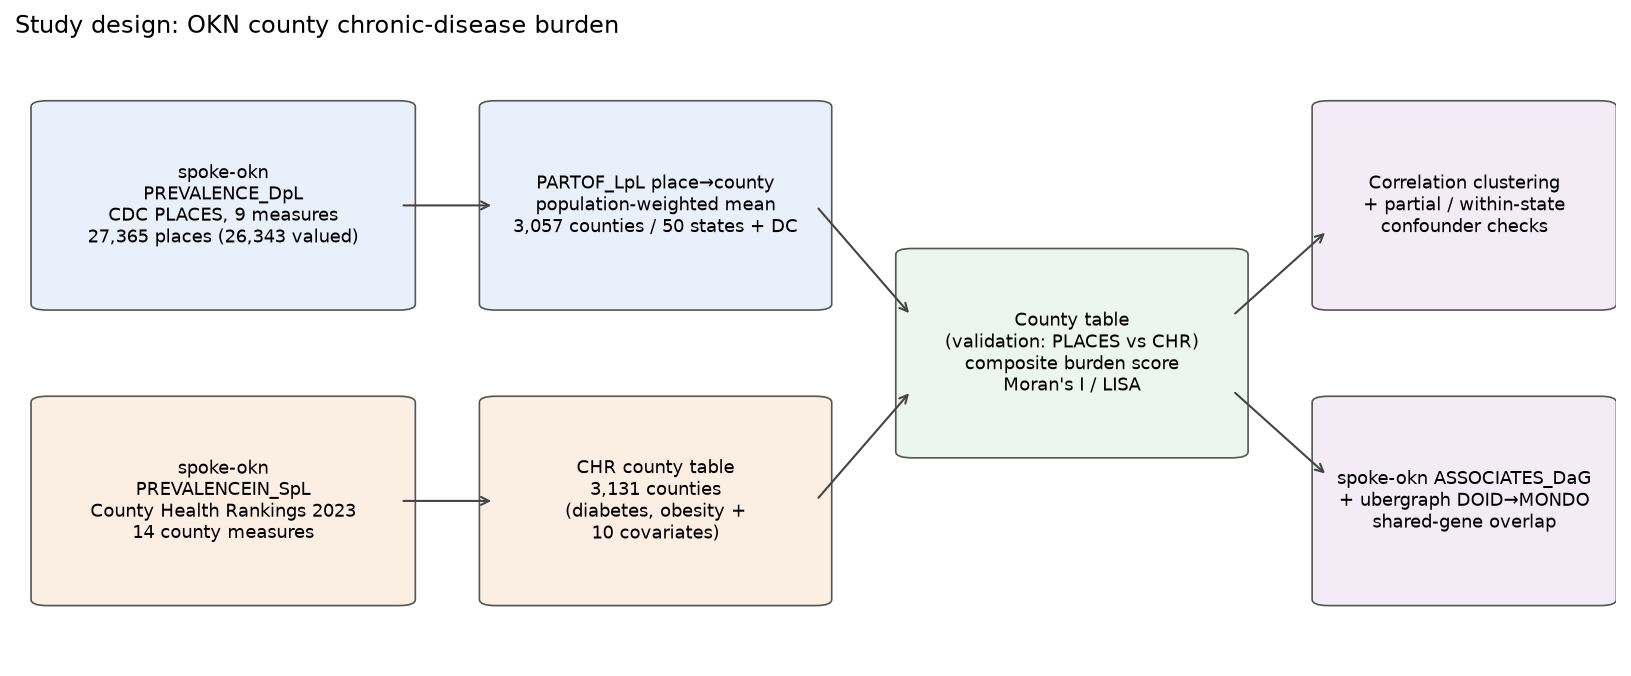

In [28]:
# Figure 1
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axis("off")
boxes = [
    (0.02, 0.58, 0.22, 0.32, "spoke-okn\nPREVALENCE_DpL\nCDC PLACES, 9 measures\n27,365 places (26,343 valued)", "#E8F1FA"),
    (0.02, 0.10, 0.22, 0.32, "spoke-okn\nPREVALENCEIN_SpL\nCounty Health Rankings 2023\n14 county measures", "#FBEFE3"),
    (0.30, 0.58, 0.20, 0.32, "PARTOF_LpL place→county\npopulation-weighted mean\n3,057 counties / 50 states + DC", "#E8F1FA"),
    (0.30, 0.10, 0.20, 0.32, "CHR county table\n3,131 counties\n(diabetes, obesity +\n10 covariates)", "#FBEFE3"),
    (0.56, 0.34, 0.20, 0.32, "County table\n(validation: PLACES vs CHR)\ncomposite burden score\nMoran's I / LISA", "#EAF6EE"),
    (0.82, 0.58, 0.17, 0.32, "Correlation clustering\n+ partial / within-state\nconfounder checks", "#F3ECF7"),
    (0.82, 0.10, 0.17, 0.32, "spoke-okn ASSOCIATES_DaG\n+ ubergraph DOID→MONDO\nshared-gene overlap", "#F3ECF7"),
]
for x, y, wd, ht, txt, col in boxes:
    ax.add_patch(mpatches.FancyBboxPatch((x, y), wd, ht, boxstyle="round,pad=0.01", fc=col, ec="#555", lw=0.8))
    ax.text(x + wd / 2, y + ht / 2, txt, ha="center", va="center", fontsize=8.5)
for (x1, y1, x2, y2) in [(0.24, 0.74, 0.30, 0.74), (0.24, 0.26, 0.30, 0.26), (0.50, 0.74, 0.56, 0.56),
                         (0.50, 0.26, 0.56, 0.44), (0.76, 0.56, 0.82, 0.70), (0.76, 0.44, 0.82, 0.30)]:
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#444", lw=1))
ax.set_title("Study design: OKN county chronic-disease burden", fontsize=11.5, loc="left")
F.finalize(fig, 1, os.path.join(FIG, "fig1_study_design.png"))

***Figure 1. Study design.*** Data flow from the two spoke-okn health layers (PLACES place prevalence, CHR county measures) through place→county aggregation to the county table, composite scoring and spatial statistics, then the correlation/confounder analyses and the cross-KG shared-gene layer (spoke-okn ASSOCIATES_DaG plus ubergraph DOID→MONDO). Provenance: logged SPARQL queries q01–q20 in the reproducibility notebook.

[okn_figstyle] saved Figure 2: figures/fig2_validation_places_vs_chr.png


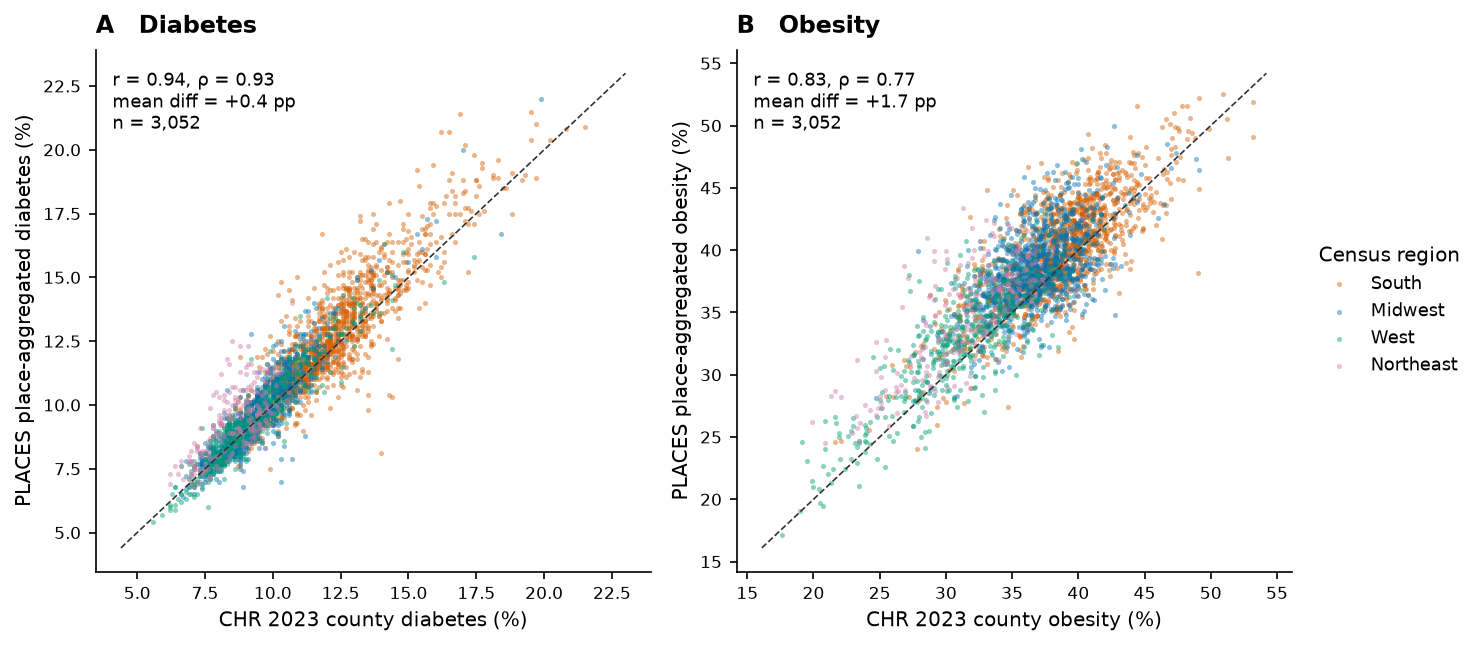

In [29]:
# Figure 2
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, (k, ck, letter) in zip(axes, [("diabetes", "chr_diabetes", "A"), ("obesity", "chr_obesity", "B")]):
    d = m[[k, ck, "region"]].dropna()
    for reg, col in REGCOL.items():
        s = d[d.region == reg]
        ax.scatter(s[ck], s[k], s=6, alpha=0.45, color=col, label=reg, lw=0)
    lim = [min(d[k].min(), d[ck].min()) - 1, max(d[k].max(), d[ck].max()) + 1]
    ax.plot(lim, lim, color="#333", lw=0.8, ls="--")
    v = val[val.condition == A.LABEL[k]].iloc[0]
    ax.text(0.03, 0.96, f"r = {v.pearson_r:.2f}, ρ = {v.spearman_rho:.2f}\nmean diff = {v.mean_diff_pp:+.1f} pp\nn = {int(v.n):,}",
            transform=ax.transAxes, va="top", fontsize=8.5)
    ax.set_xlabel(f"CHR 2023 county {A.LABEL[k].lower()} (%)")
    ax.set_ylabel(f"PLACES place-aggregated {A.LABEL[k].lower()} (%)")
    F.panel_title(ax, letter, A.LABEL[k])
F.legend_outside(axes[1], where="right", title="Census region")
F.finalize(fig, 2, os.path.join(FIG, "fig2_validation_places_vs_chr.png"))

***Figure 2. PLACES place-aggregated county prevalence vs County Health Rankings 2023.*** **(A)** Diabetes, **(B)** obesity; one point per county, coloured by Census region; dashed line = identity. Inset: Pearson r, Spearman ρ, mean difference (PLACES − CHR) and n. Provenance: spoke-okn PREVALENCE_DpL (PLACES, aggregated via PARTOF_LpL) vs spoke-okn PREVALENCEIN_SpL (source "County Health Rankings").

[okn_figstyle] saved Figure 3: figures/fig3_prevalence_distributions.png


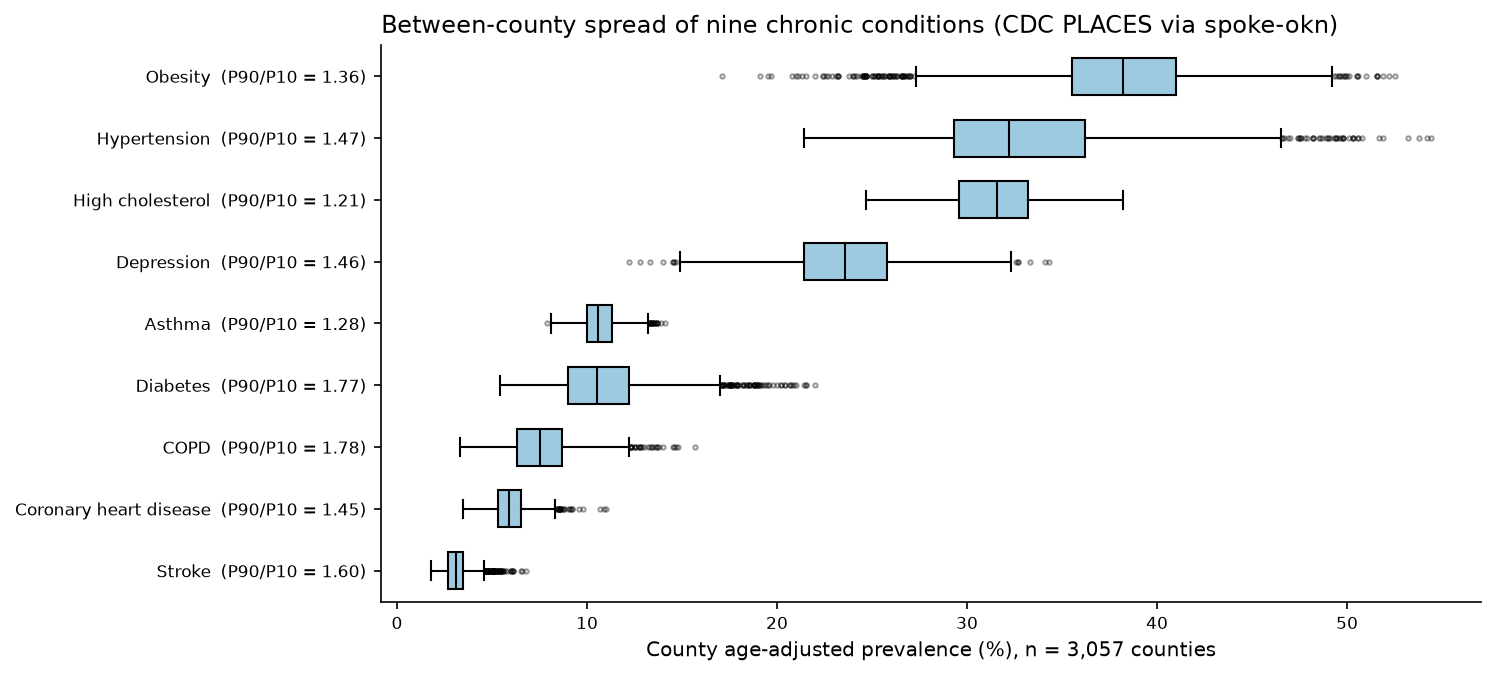

In [30]:
# Figure 3
fig, ax = plt.subplots(figsize=(10, 4.6))
ordk = summ.sort_values("median", ascending=False)["condition"].tolist()
keys = [k for lab in ordk for k in A.DKEYS if A.LABEL[k] == lab]
bp = ax.boxplot([m[k].dropna() for k in keys], orientation="horizontal", patch_artist=True, widths=0.6,
                flierprops=dict(markersize=2, alpha=0.4), medianprops=dict(color="#000"))
for patch, k in zip(bp["boxes"], keys):
    patch.set_facecolor("#9ecae1")
ax.set_yticks(range(1, len(keys) + 1))
ax.set_yticklabels([f"{A.LABEL[k]}  (P90/P10 = {summ.set_index('condition').loc[A.LABEL[k], 'fold_p90_p10']:.2f})" for k in keys])
ax.invert_yaxis()
ax.set_xlabel("County age-adjusted prevalence (%), n = 3,057 counties")
ax.set_title("Between-county spread of nine chronic conditions (CDC PLACES via spoke-okn)", loc="left")
F.finalize(fig, 3, os.path.join(FIG, "fig3_prevalence_distributions.png"))

***Figure 3. Distribution of county age-adjusted prevalence for the nine conditions*** (n = 3057 counties; box = interquartile range, whiskers 1.5 × IQR, points = outliers). Labels give the ratio of the 90th to 10th percentile. Provenance: spoke-okn PREVALENCE_DpL (CDC PLACES) aggregated to county.

[okn_figstyle] saved Figure 4: figures/fig4_condition_maps.png


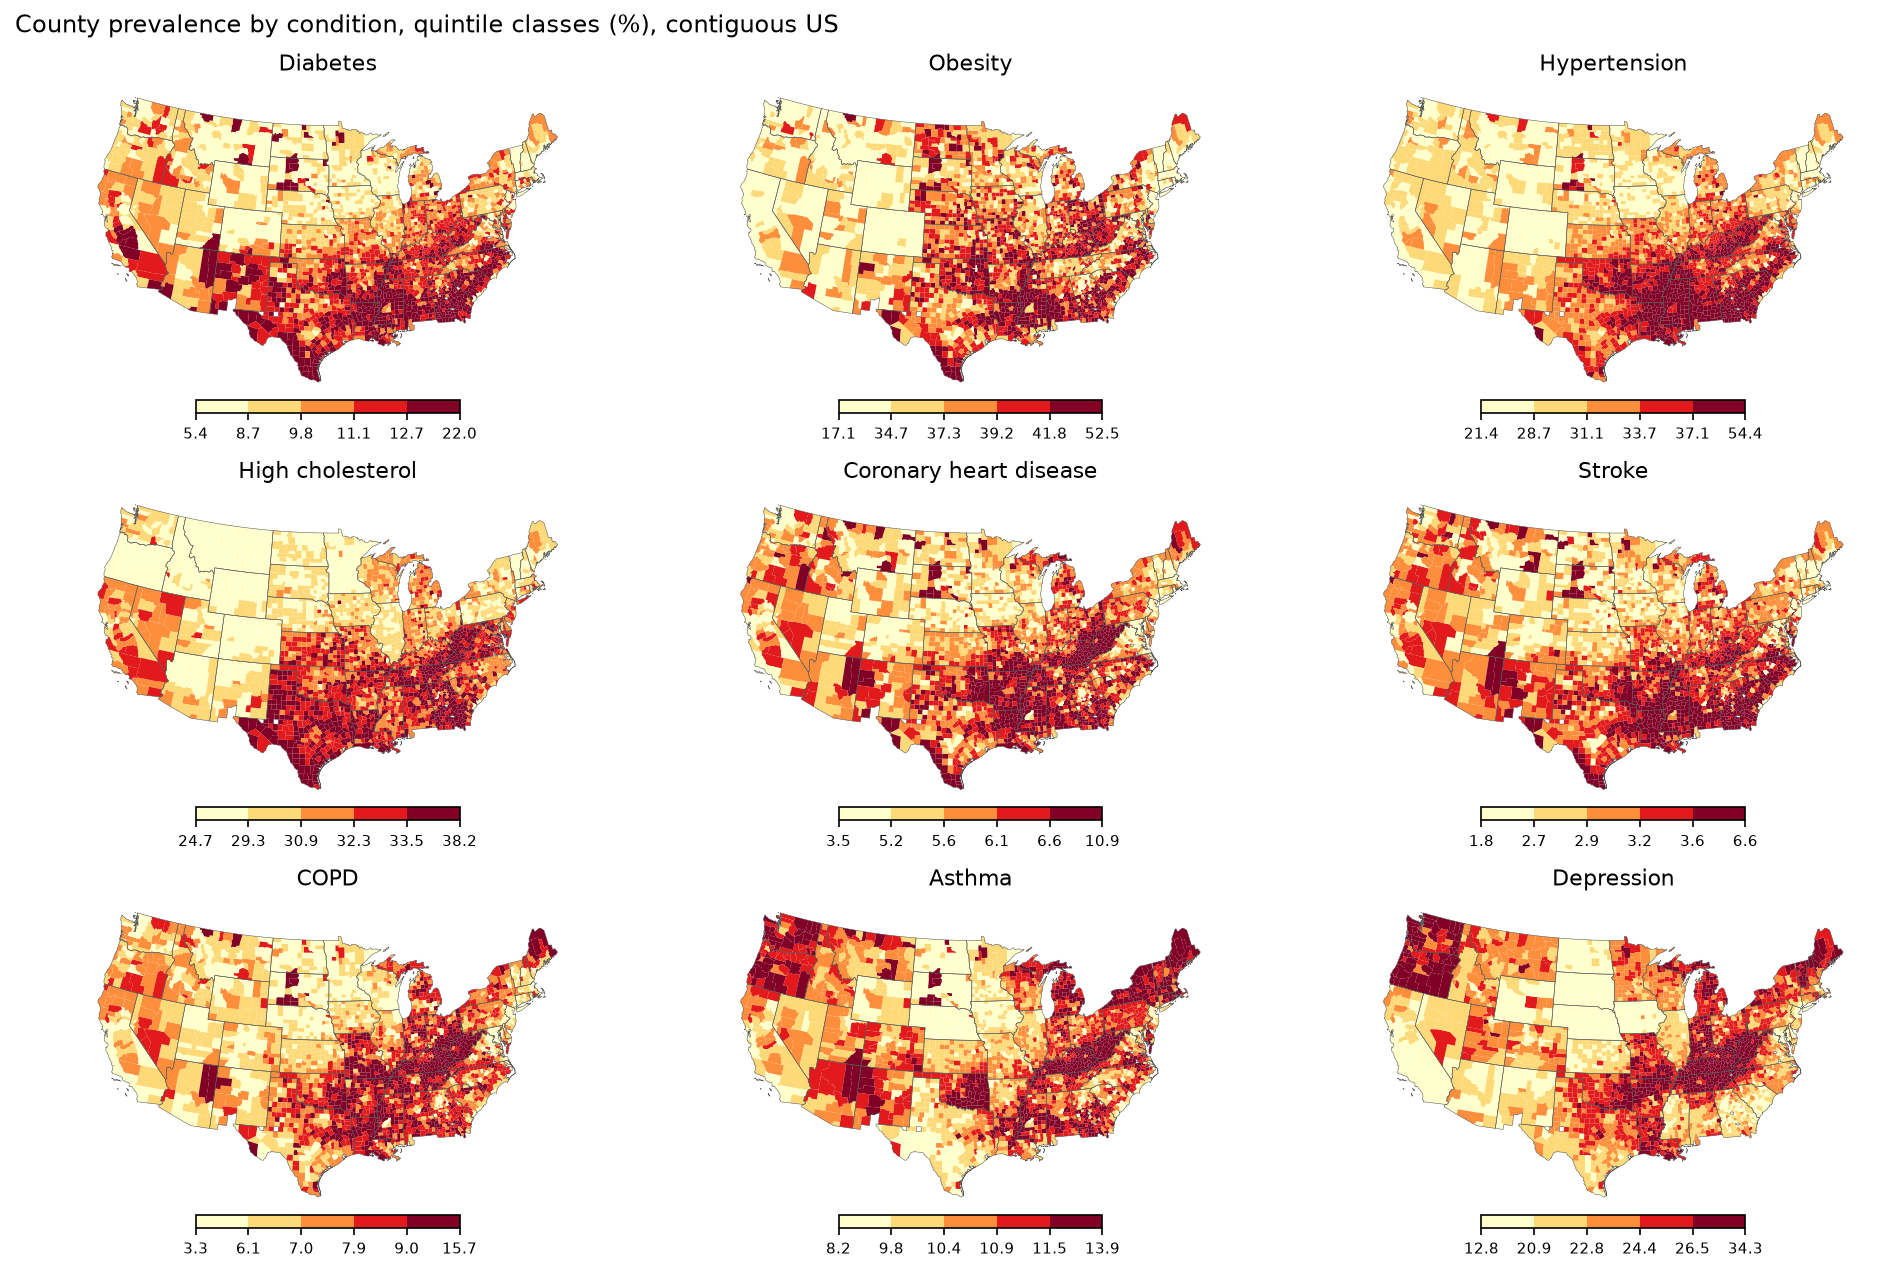

In [31]:
# Figure 4
fig, axes = plt.subplots(3, 3, figsize=(13, 8.6))
for ax, k in zip(axes.flat, A.DKEYS):
    q = np.nanquantile(conus[k], [0, .2, .4, .6, .8, 1])
    norm = BoundaryNorm(q, 256)
    conus.plot(column=k, ax=ax, cmap="YlOrRd", norm=norm, linewidth=0, edgecolor="none")
    states.boundary.plot(ax=ax, color="#555", linewidth=0.25)
    ax.set_axis_off()
    ax.set_title(A.LABEL[k], fontsize=10.5)
    sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=norm)
    cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.04, pad=0.01, ticks=q)
    cb.ax.set_xticklabels([f"{v:.1f}" for v in q], fontsize=7)
fig.suptitle("County prevalence by condition, quintile classes (%), contiguous US", fontsize=11.5, x=0.01, ha="left")
F.finalize(fig, 4, os.path.join(FIG, "fig4_condition_maps.png"))

***Figure 4. County prevalence by condition, contiguous US.*** Quintile classes per condition (colour bar ticks = class breaks, %); grey = no PLACES data (all of Florida and counties without linked places); state outlines for reference. Alaska and Hawaii appear in the interactive map below. Provenance: spoke-okn PREVALENCE_DpL (PLACES) aggregated via PARTOF_LpL; boundaries from the Census 2010 cartographic file.

[okn_figstyle] saved Figure 5: figures/fig5_composite_burden_hotspots.png


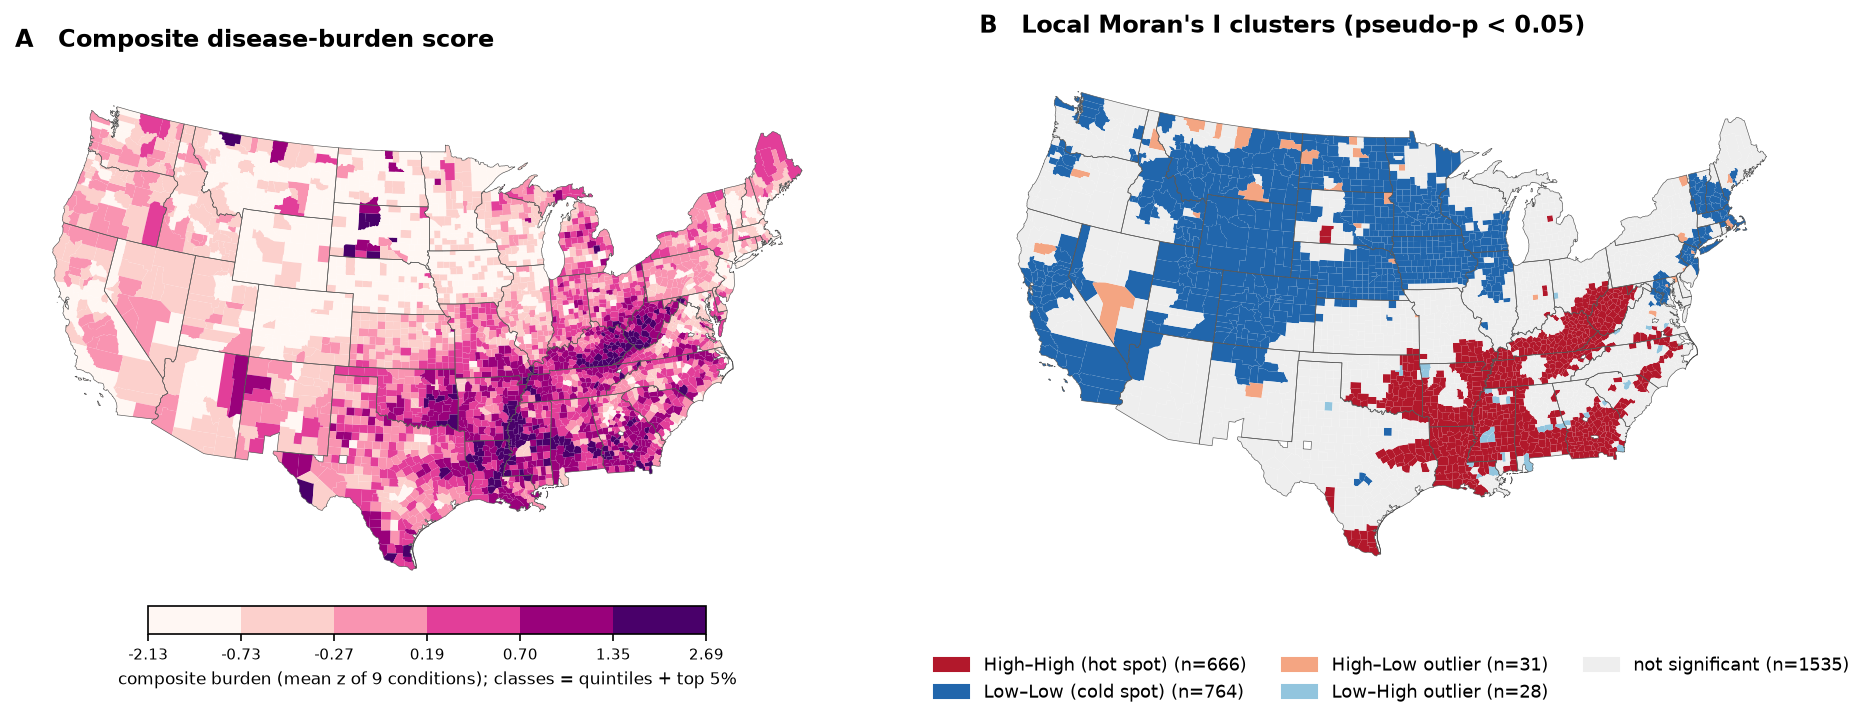

In [32]:
# Figure 5
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
q = np.nanquantile(conus["burden_z"], [0, .2, .4, .6, .8, .95, 1])
norm = BoundaryNorm(q, 256)
conus.plot(column="burden_z", ax=axes[0], cmap="RdPu", norm=norm, linewidth=0)
states.boundary.plot(ax=axes[0], color="#555", linewidth=0.3)
sm = plt.cm.ScalarMappable(cmap="RdPu", norm=norm)
cb = fig.colorbar(sm, ax=axes[0], orientation="horizontal", fraction=0.045, pad=0.02, ticks=q)
cb.ax.set_xticklabels([f"{v:.2f}" for v in q], fontsize=7)
cb.set_label("composite burden (mean z of 9 conditions); classes = quintiles + top 5%", fontsize=8)
F.panel_title(axes[0], "A", "Composite disease-burden score")
lc = {"HH": "#b2182b", "LL": "#2166ac", "HL": "#f4a582", "LH": "#92c5de", "ns": "#eeeeee"}
for lab, col in lc.items():
    s = conus[conus.lisa == lab]
    if len(s):
        s.plot(ax=axes[1], color=col, linewidth=0)
states.boundary.plot(ax=axes[1], color="#555", linewidth=0.3)
F.panel_title(axes[1], "B", "Local Moran's I clusters (pseudo-p < 0.05)")
names = {"HH": "High–High (hot spot)", "LL": "Low–Low (cold spot)", "HL": "High–Low outlier", "LH": "Low–High outlier", "ns": "not significant"}
F.legend_outside(axes[1], [mpatches.Patch(color=lc[k]) for k in lc], [f"{names[k]} (n={int((conus.lisa == k).sum())})" for k in lc],
                 where="below", ncol=3)
for ax in axes:
    ax.set_axis_off()
F.finalize(fig, 5, os.path.join(FIG, "fig5_composite_burden_hotspots.png"))

***Figure 5. Composite disease burden.*** **(A)** Composite score (mean z of nine conditions), classes = quintiles plus the top 5%. **(B)** Local Moran's I clusters at pseudo-p < 0.05 (999 permutations; 6-nearest-neighbour weights): High–High = high-burden county surrounded by high-burden neighbours. Provenance: as Figure 4; spatial statistics with PySAL esda.

[okn_figstyle] saved Figure 6: figures/fig6_top_counties_multimorbidity.png


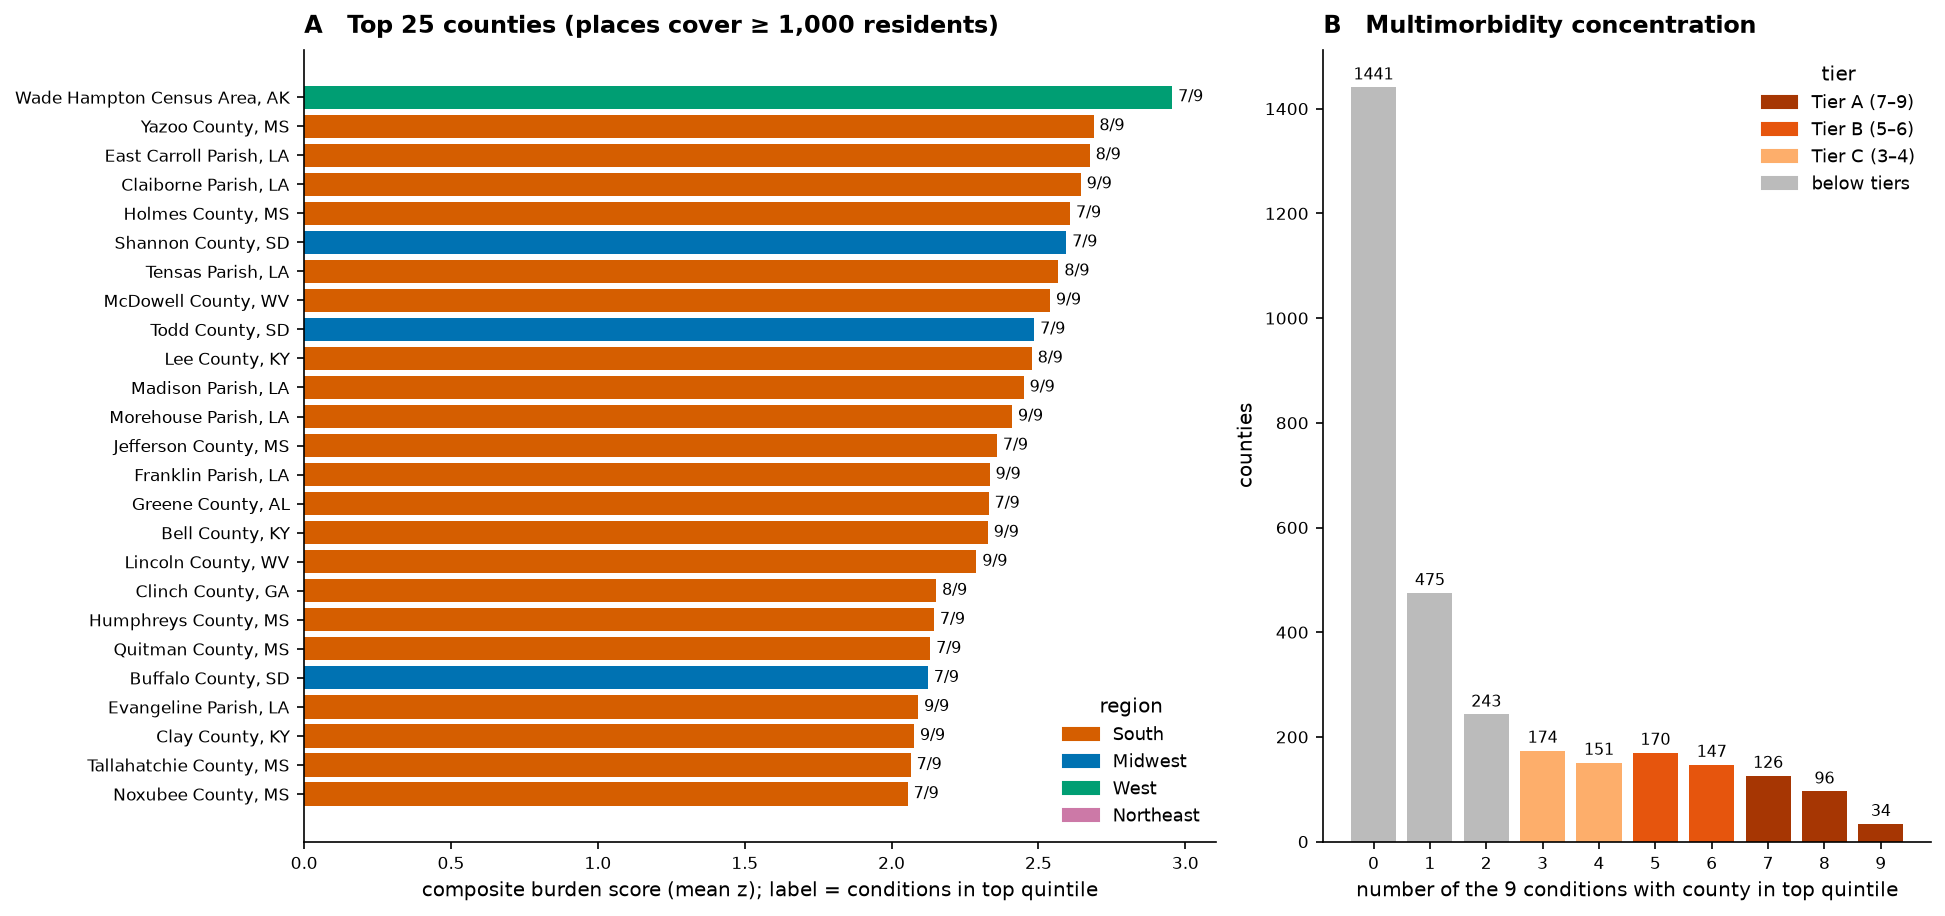

In [33]:
# Figure 6
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1.5, 1]})
t = m[m.eligible].nlargest(25, "burden_z").iloc[::-1]
axes[0].barh(range(len(t)), t["burden_z"], color=[REGCOL[r] for r in t.region])
axes[0].set_yticks(range(len(t)))
axes[0].set_yticklabels(t["name"], fontsize=8)
for i, (_, r) in enumerate(t.iterrows()):
    axes[0].text(r.burden_z + 0.02, i, f"{int(r.n_top_quintile)}/9", va="center", fontsize=7.5)
axes[0].set_xlabel("composite burden score (mean z); label = conditions in top quintile")
F.panel_title(axes[0], "A", "Top 25 counties (places cover ≥ 1,000 residents)")
F.theme_legend(axes[0], REGCOL, where="lower right", title="region")
cnt = m["n_top_quintile"].value_counts().sort_index()
cols = ["#bbbbbb" if i < 3 else ("#fdae6b" if i < A.MULTI_K else ("#e6550d" if i < 7 else "#a63603")) for i in cnt.index]
axes[1].bar(cnt.index, cnt.values, color=cols)
for x, y in cnt.items():
    axes[1].text(x, y + 15, str(y), ha="center", fontsize=7.5)
axes[1].set_xlabel("number of the 9 conditions with county in top quintile")
axes[1].set_ylabel("counties")
axes[1].set_xticks(range(0, 10))
F.panel_title(axes[1], "B", "Multimorbidity concentration")
F.theme_legend(axes[1], {"Tier A (7–9)": "#a63603", "Tier B (5–6)": "#e6550d", "Tier C (3–4)": "#fdae6b", "below tiers": "#bbbbbb"},
               where="upper right", title="tier")
F.finalize(fig, 6, os.path.join(FIG, "fig6_top_counties_multimorbidity.png"))

***Figure 6. Highest-burden counties and multimorbidity concentration.*** **(A)** The 25 highest composite scores among counties whose places cover ≥ 1000 residents, coloured by Census region; labels = number of the nine conditions in the national top quintile. **(B)** Distribution of that count across all 3057 counties, coloured by tier (§4). Provenance: spoke-okn PLACES aggregated to county.

[okn_figstyle] saved Figure 7: figures/fig7_clustered_correlation_heatmaps.png


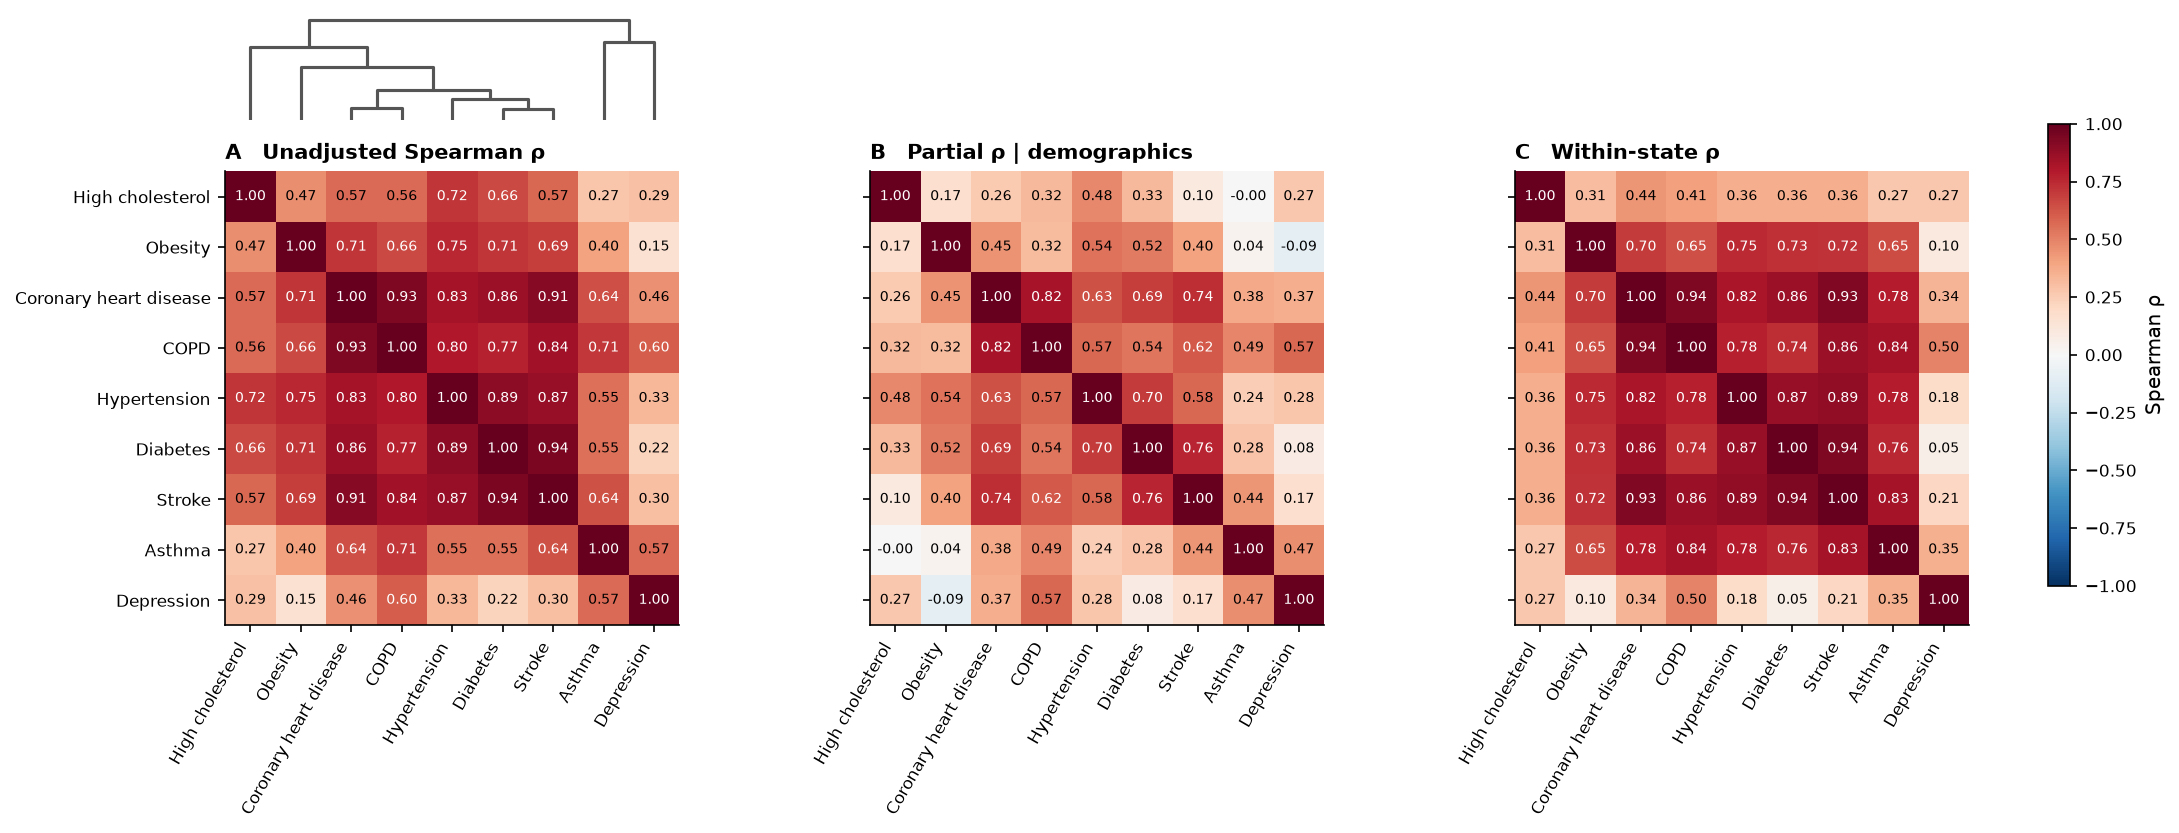

In [34]:
# Figure 7
fig = plt.figure(figsize=(15, 5.6))
gs = fig.add_gridspec(2, 3, height_ratios=[0.6, 3], hspace=0.05, wspace=0.42)
labs = [A.LABEL[k] for k in order]
axd = fig.add_subplot(gs[0, 0])
dendrogram(Z, ax=axd, labels=None, color_threshold=0, above_threshold_color="#555", no_labels=True)
axd.set_axis_off()
for j, (mat, title, letter) in enumerate([(raw, "Unadjusted Spearman ρ", "A"),
                                          (part, "Partial ρ | demographics", "B"),
                                          (ws, "Within-state ρ", "C")]):
    ax = fig.add_subplot(gs[1, j])
    M = mat.loc[order, order].to_numpy()
    im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(9))
    ax.set_yticks(range(9))
    ax.set_xticklabels(labs, rotation=60, ha="right", fontsize=8)
    ax.set_yticklabels(labs if j == 0 else [""] * 9, fontsize=8)
    for a in range(9):
        for b in range(9):
            ax.text(b, a, f"{M[a, b]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(M[a, b]) > 0.6 else "black")
    ax.set_title(f"{letter}   {title}", fontsize=10, loc="left", fontweight="bold")
cax = fig.add_axes([0.935, 0.2, 0.01, 0.55])
fig.colorbar(im, cax=cax, label="Spearman ρ")
F.finalize(fig, 7, os.path.join(FIG, "fig7_clustered_correlation_heatmaps.png"))

***Figure 7. Clustered county-level correlation among the nine conditions.*** **(A)** Unadjusted Spearman ρ (n = 3057), rows/columns ordered by average-linkage clustering on 1 − ρ (dendrogram above). **(B)** Partial ρ after rank-residualising every condition on seven CHR demographic covariates (% aged 65+, % non-Hispanic Black, % Hispanic, % rural, % children in poverty, % some college, % uninsured adults; n = 3049). **(C)** Within-state ρ (state means removed from ranks). Same ordering in all panels; diverging scale centred at 0. Provenance: spoke-okn PLACES (aggregated) and CHR 2023.

[okn_figstyle] saved Figure 8: figures/fig8_confounders_variance_explained.png


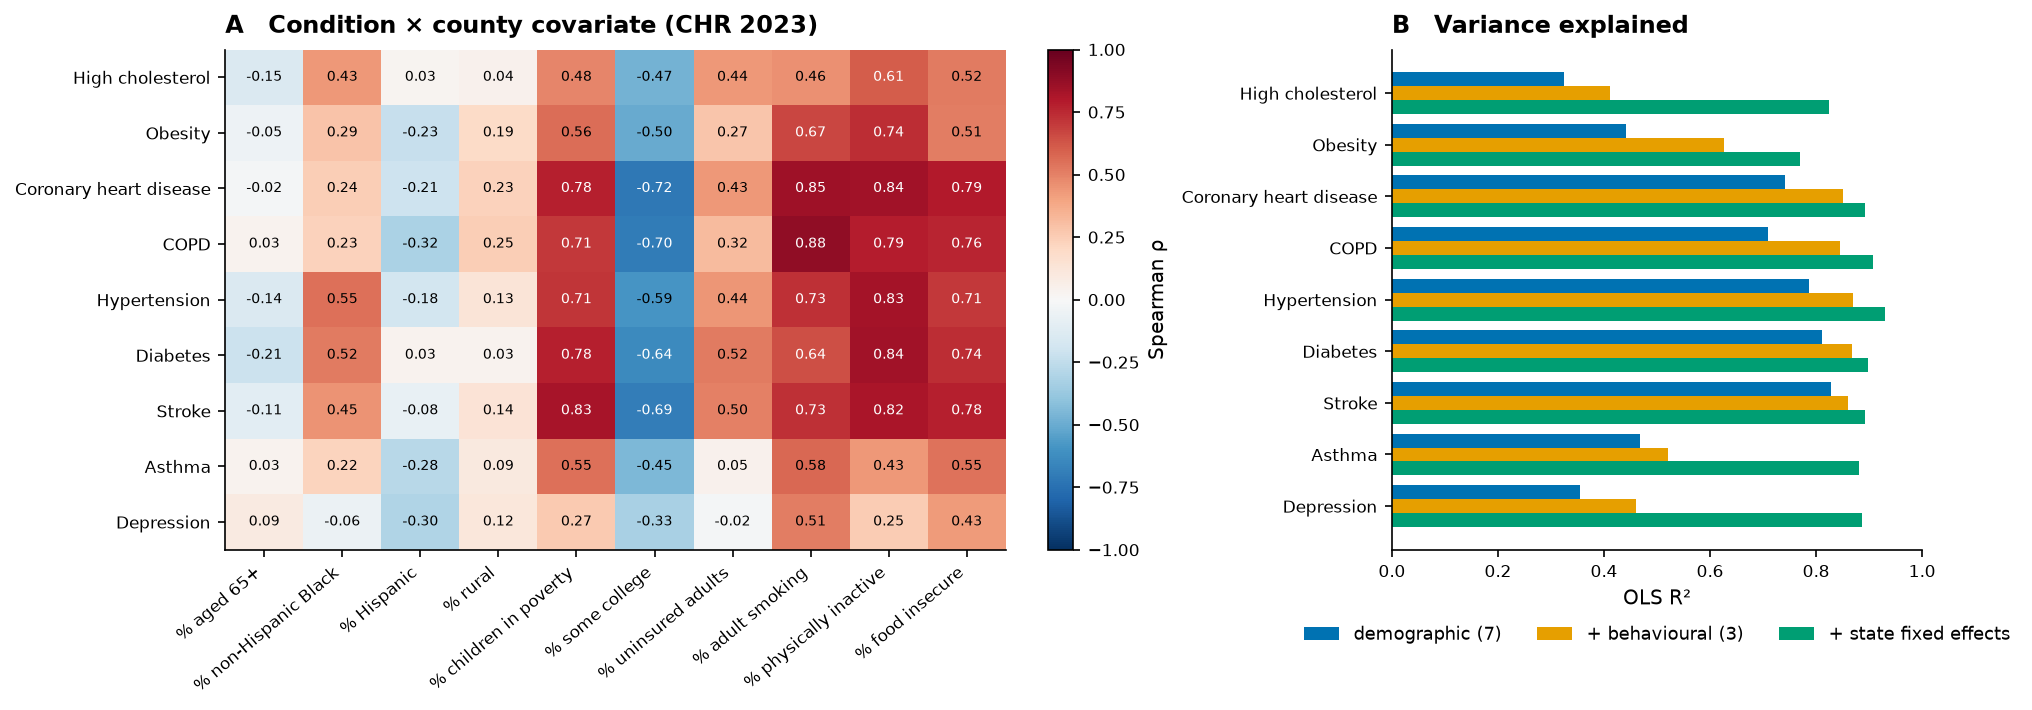

In [35]:
# Figure 8
labs = [A.LABEL[k] for k in order]  # Figure 7 order
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
C = conf.loc[order]
im = axes[0].imshow(C.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
axes[0].set_xticks(range(C.shape[1]))
axes[0].set_xticklabels([A.CONFOUNDERS[c] for c in C.columns], rotation=40, ha="right", fontsize=8)
axes[0].set_yticks(range(9))
axes[0].set_yticklabels(labs, fontsize=8)
for a in range(C.shape[0]):
    for b in range(C.shape[1]):
        axes[0].text(b, a, f"{C.iloc[a, b]:.2f}", ha="center", va="center", fontsize=6.5,
                     color="white" if abs(C.iloc[a, b]) > 0.6 else "black")
fig.colorbar(im, ax=axes[0], fraction=0.03, label="Spearman ρ")
F.panel_title(axes[0], "A", "Condition × county covariate (CHR 2023)")
R = r2.set_index("condition").loc[labs]
y = np.arange(9)
axes[1].barh(y - 0.27, R["R2_demographic"], 0.27, color="#0072B2", label="demographic (7)")
axes[1].barh(y, R["R2_demo_behavioural"], 0.27, color="#E69F00", label="+ behavioural (3)")
axes[1].barh(y + 0.27, R["R2_demo_behav_state"], 0.27, color="#009E73", label="+ state fixed effects")
axes[1].set_yticks(y)
axes[1].set_yticklabels(labs, fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("OLS R²")
F.panel_title(axes[1], "B", "Variance explained")
F.legend_outside(axes[1], where="below", ncol=3)
F.finalize(fig, 8, os.path.join(FIG, "fig8_confounders_variance_explained.png"))

***Figure 8. County covariates and variance explained.*** **(A)** Spearman ρ between each condition (rows, Figure 7 order) and ten CHR 2023 county covariates. **(B)** OLS R² of each condition on the seven demographic covariates, after adding three behavioural covariates, and after adding state fixed effects. Provenance: spoke-okn PREVALENCEIN_SpL (County Health Rankings 2023) joined on county FIPS to aggregated PLACES.

[okn_figstyle] saved Figure 9: figures/fig9_gene_overlap_vs_geography.png


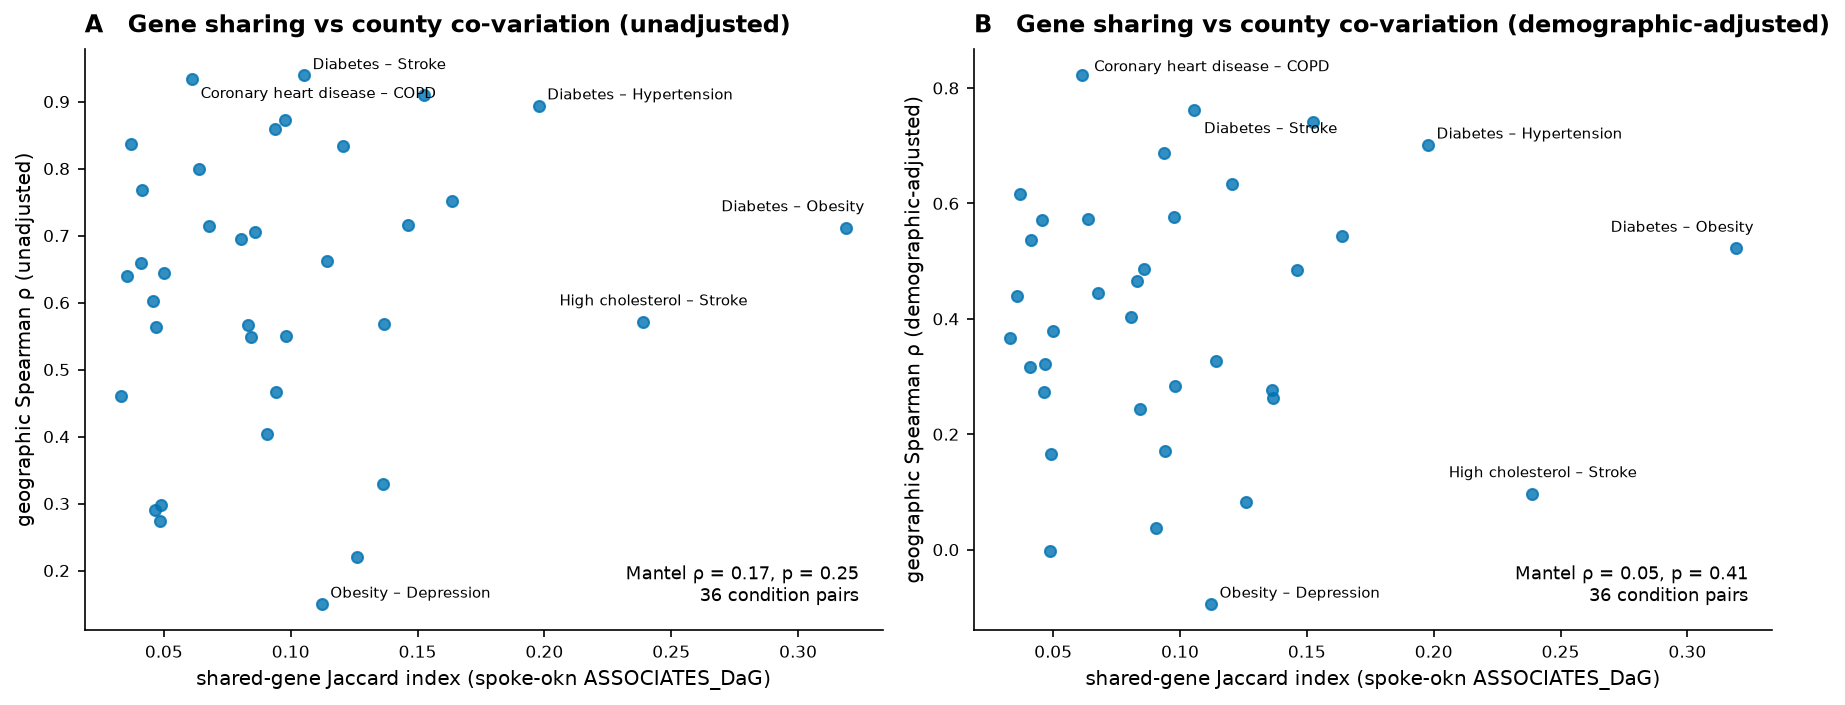

In [36]:
# Figure 9
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
gt = gene_t.merge(pairs[["a", "b", "rho_raw", "rho_partial_demo"]], on=["a", "b"])
for ax, col, letter, ttl, mt in [(axes[0], "rho_raw", "A", "unadjusted", mantel_raw),
                                 (axes[1], "rho_partial_demo", "B", "demographic-adjusted", mantel_part)]:
    ax.scatter(gt["jaccard"], gt[col], s=28, color="#0072B2", alpha=0.8)
    LAB = {("diabetes", "obesity"): (-60, 8), ("high_chol", "stroke"): (-40, 8), ("diabetes", "stroke"): (4, 3),
           ("chd", "copd"): (4, -9), ("obesity", "depression"): (4, 3), ("diabetes", "hypertension"): (4, 3)}
    for _, r in gt.iterrows():
        off = LAB.get((r.a, r.b))
        if col == "rho_partial_demo" and (r.a, r.b) == ("chd", "copd"):
            off = (6, 2)
        if col == "rho_partial_demo" and (r.a, r.b) == ("diabetes", "stroke"):
            off = (5, -11)
        if off:
            ax.annotate(r.pair, (r.jaccard, r[col]), fontsize=7, xytext=off, textcoords="offset points")
    ax.set_xlabel("shared-gene Jaccard index (spoke-okn ASSOCIATES_DaG)")
    ax.set_ylabel(f"geographic Spearman ρ ({ttl})")
    ax.text(0.97, 0.04, f"Mantel ρ = {mt[0]:.2f}, p = {mt[1]:.2f}\n36 condition pairs", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8.5)
    F.panel_title(ax, letter, f"Gene sharing vs county co-variation ({ttl})")
F.finalize(fig, 9, os.path.join(FIG, "fig9_gene_overlap_vs_geography.png"))

***Figure 9. Shared disease-associated genes vs county co-variation.*** Each point is one of the 36 condition pairs. x = Jaccard index of their spoke-okn gene sets (ASSOCIATES_DaG; diseases identified as DOID and mapped to MONDO through ubergraph); y = county Spearman ρ, **(A)** unadjusted, **(B)** demographic-adjusted. Inset: Mantel test (Spearman, 9,999 permutations). Provenance: spoke-okn ASSOCIATES_DaG (gene background = 6666 genes with any disease association), ubergraph skos:exactMatch.

In [37]:
# Interactive county map: drop-down selects the composite score, any of the 9 conditions, or the
# top-quintile count (one GeoJson layer restyled by setStyle; Esri World Street Map tiles).
import json
import folium
from IPython.display import HTML

mm = pd.read_csv("outputs/county_burden_ranked.tsv", sep="\t", dtype={"fips": str})
gm = gpd.read_file(GEO)
gm["fips"] = gm["id"].astype(str).str.zfill(5)
gm = gm.merge(mm, on="fips", how="left")
gm = gm[~gm["fips"].str[:2].isin(["72"])]  # drop Puerto Rico (outside PLACES scope here)
gm["name"] = gm["name"].fillna(gm["NAME"] + " (no PLACES data)")
gm["tier"] = gm["tier"].fillna("n/a")
gm["geometry"] = gm.geometry.simplify(0.01, preserve_topology=True)

VARS = [("burden_z", "Composite burden score (mean z)")] + [(k, A.LABEL[k] + " (%)") for k in A.DKEYS] + [
    ("n_top_quintile", "Conditions in top quintile (0–9)")]
props = ["fips", "name", "tier", "pop_places"] + [v for v, _ in VARS]
for v, _ in VARS:
    gm[v] = gm[v].astype(float).round(2)
gj = json.loads(gm[props + ["geometry"]].to_json())
breaks = {v: [float(x) for x in np.nanquantile(gm[v], [0.2, 0.4, 0.6, 0.8])] for v, _ in VARS}
breaks["n_top_quintile"] = [1, 3, 5, 7]
COLORS = ["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"]

fm = folium.Map(location=[38.5, -96], zoom_start=4, tiles=F.BASEMAP_TILES, attr=F.BASEMAP_ATTR, control_scale=True)
layer = folium.GeoJson(
    gj, name="counties",
    style_function=lambda f: {"fillColor": "#cccccc", "color": "#666", "weight": 0.2, "fillOpacity": 0.75},
    highlight_function=lambda f: {"weight": 1.5, "color": "#000"},
    tooltip=folium.GeoJsonTooltip(fields=["name", "burden_z", "tier"], aliases=["County", "Composite z", "Tier"]),
    popup=folium.GeoJsonPopup(fields=props[1:], aliases=["County", "Tier", "Pop. in PLACES places"] + [l for _, l in VARS]),
).add_to(fm)
lname, mname = layer.get_name(), fm.get_name()
opts = "".join(f'<option value="{v}">{l}</option>' for v, l in VARS)
ctrl = f"""
<div id="ctrl" style="position:absolute;top:10px;right:10px;z-index:9999;background:white;padding:8px 10px;
 border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font:12px sans-serif;max-width:250px">
 <b>Map variable</b><br><select id="varsel" style="margin:4px 0;font-size:12px;max-width:230px">{opts}</select>
 <div id="leg"></div><div style="color:#555;margin-top:4px">Quintile classes · grey = no PLACES data
 (incl. all of Florida). Click a county for all values.</div></div>
<script>
(function(){{
 var B={json.dumps(breaks)}, C={json.dumps(COLORS)}, L={json.dumps(dict(VARS))};
 function col(v,b){{ if(v===null||v===undefined||isNaN(v)) return '#cccccc';
   for(var i=0;i<b.length;i++){{ if(v<=b[i]) return C[i]; }} return C[4]; }}
 function apply(){{
   var k=document.getElementById('varsel').value, b=B[k];
   {lname}.setStyle(function(f){{return {{fillColor:col(f.properties[k],b),color:'#666',weight:0.2,fillOpacity:0.75}};}});
   var h='<div style="margin-top:4px">'+L[k]+'</div>', lo='min';
   for(var i=0;i<5;i++){{ var hi=(i<4)?b[i].toFixed(2):'max';
     h+='<div><span style="display:inline-block;width:14px;height:10px;background:'+C[i]+';margin-right:5px"></span>'+lo+' – '+hi+'</div>';
     lo=(i<4)?b[i].toFixed(2):''; }}
   document.getElementById('leg').innerHTML=h; }}
 document.getElementById('varsel').addEventListener('change',apply);
 var t=setInterval(function(){{ if(typeof {lname}!=='undefined'){{ clearInterval(t); apply(); }} }},100);
}})();
</script>"""
fm.get_root().html.add_child(folium.Element(ctrl))
frag = F.folium_map_iframe(fm, height=620, title="Interactive county chronic-disease map")
open("outputs/map_fragment.html", "w").write(frag)
HTML(frag)

*Interactive map: Leaflet/folium choropleth on Esri World Street Map tiles; one GeoJSON layer restyled per selected variable with quintile classes; counties with no PLACES data are grey. Values from data/county_burden_ranked.tsv.*

In [38]:
# Headline numbers -> outputs/stats.json, checked against the report.
tierc = m["tier"].value_counts()
hh = conus[conus.lisa == "HH"]
top1 = m[m.eligible].nlargest(1, "burden_z").iloc[0]
pt = pairs.set_index("pair")


def pr(a, b, col="rho_raw"):
    return round(float(pairs[((pairs.a == a) & (pairs.b == b)) | ((pairs.a == b) & (pairs.b == a))][col].iloc[0]), 2)


S = {
    "n_places_total": 27365, "n_places_valued": 26343, "n_places_unlinked": 1207,
    "n_counties_places": int(len(m)), "n_counties_chr": int(chr_["fips"].nunique()),
    "n_counties_eligible": int(m.eligible.sum()), "n_states": int(m.state.nunique()),
    "n_conditions": 9, "min_pop": A.MIN_POP,
    "val_diab_r": round(float(val.iloc[0].pearson_r), 2), "val_diab_diff": round(float(val.iloc[0].mean_diff_pp), 2),
    "val_ob_r": round(float(val.iloc[1].pearson_r), 2), "val_ob_diff": round(float(val.iloc[1].mean_diff_pp), 2),
    "pc1_var_pct": round(100 * pc1_var, 1),
    "rob_min": round(float(rob.to_numpy()[np.triu_indices(5, 1)].min()), 3),
    "tier_A": int(tierc.get("A", 0)), "tier_B": int(tierc.get("B", 0)), "tier_C": int(tierc.get("C", 0)),
    "tier_AB": int(tierc.get("A", 0) + tierc.get("B", 0)),
    "n_HH": int((conus.lisa == "HH").sum()), "n_LL": int((conus.lisa == "LL").sum()),
    "HH_south_pct": round(100 * (hh.region == "South").mean(), 1),
    "moran_burden": round(float(mor.set_index("variable").loc["burden_z", "morans_I"]), 2),
    "moran_min": round(float(mor.morans_I.min()), 2), "moran_max": round(float(mor.morans_I.max()), 2),
    "top1_name": top1["name"], "top1_z": round(float(top1.burden_z), 2),
    "rho_diab_stroke": pr("diabetes", "stroke"), "rho_chd_copd": pr("chd", "copd"),
    "rho_diab_obes": pr("diabetes", "obesity"), "rho_diab_obes_part": pr("diabetes", "obesity", "rho_partial_demo"),
    "rho_ob_asthma": pr("obesity", "asthma"), "rho_ob_asthma_part": pr("obesity", "asthma", "rho_partial_demo"),
    "rho_diab_dep": pr("diabetes", "depression"), "rho_copd_dep": pr("copd", "depression"),
    "rho_diab_asthma": pr("diabetes", "asthma"), "rho_diab_asthma_ws": pr("diabetes", "asthma", "rho_within_state"),
    "mean_atten": round(float(pairs.attenuation.mean()), 2),
    "r2_diab_demo": round(float(r2.set_index("condition").loc["Diabetes", "R2_demographic"]), 2),
    "r2_asthma_demo": round(float(r2.set_index("condition").loc["Asthma", "R2_demographic"]), 2),
    "r2_asthma_state": round(float(r2.set_index("condition").loc["Asthma", "R2_demo_behav_state"]), 2),
    "r2_dep_demo": round(float(r2.set_index("condition").loc["Depression", "R2_demographic"]), 2),
    "r2_dep_state": round(float(r2.set_index("condition").loc["Depression", "R2_demo_behav_state"]), 2),
    "n_genes_bg": NG, "gene_pairs_sig": int((gene_t.fdr < 0.05).sum()),
    "mantel_raw": round(mantel_raw[0], 2), "mantel_raw_p": round(mantel_raw[1], 2),
    "mantel_part": round(mantel_part[0], 2), "mantel_part_p": round(mantel_part[1], 2),
    "diab_p10": round(float(summ.iloc[0].p10), 1), "diab_p90": round(float(summ.iloc[0].p90), 1),
    "diab_max": round(float(summ.iloc[0]["max"]), 1), "copd_fold": round(float(summ.set_index("condition").loc["COPD", "fold_p90_p10"]), 2),
    "life_exp_flagged": int(chr_.life_exp_flag.sum()),
    "tierA_south": int((m[m.tier == "A"].region == "South").sum()),
    "tierA_south_pct": round(100 * (m[m.tier == "A"].region == "South").mean(), 1),
    "pop_covered_m": round(float(m.pop_places.sum()) / 1e6, 1),
    "n_conus": int(len(conus)),
    "mean_rho_raw": round(float(raw.to_numpy()[np.triu_indices(9, 1)].mean()), 2),
    "mean_rho_part": round(float(part.to_numpy()[np.triu_indices(9, 1)].mean()), 2),
    "mean_rho_full": round(float(part_full.to_numpy()[np.triu_indices(9, 1)].mean()), 2),
    "mean_rho_ws": round(float(ws.to_numpy()[np.triu_indices(9, 1)].mean()), 2),
    "n_partial": int(n_part),
    "n_ineligible": int((~m.eligible).sum()),
    "kg_spoke_version": "v0.0.6", "kg_uber_version": "v0.0.2",
}
for s_, n_ in statec.head(5)["n_high"].items():
    S[f"st_{s_}"] = int(n_)
json.dump(S, open(os.path.join(DAT, "stats.json"), "w"), indent=1)

expected = {"n_counties_places": 3057, "n_counties_eligible": 2930, "val_diab_r": 0.94, "val_ob_r": 0.83,
            "pc1_var_pct": 66.7, "tier_A": 256, "tier_B": 317, "tier_C": 325, "moran_burden": 0.71,
            "n_HH": 666, "mean_rho_raw": 0.62, "mean_rho_part": 0.40, "mean_rho_full": 0.31,
            "rho_ob_asthma_part": 0.04, "mantel_raw": 0.17, "gene_pairs_sig": 33}
bad = {k: (S.get(k), v) for k, v in expected.items() if S.get(k) is None or abs(float(S[k]) - v) > 0.006}
print("all headline numbers reproduced" if not bad else f"MISMATCH: {bad}")

all headline numbers reproduced


## Key findings

1. **Coverage.** spoke-okn carries CDC PLACES age-adjusted prevalence for 9 chronic conditions at place level; aggregated to **3,057 counties** (50 states + DC, ~176 M residents in places). Florida is absent — the main data gap. PLACES-derived county values agree with independent County Health Rankings 2023 (diabetes r = 0.94; obesity r = 0.83, PLACES ~1.7 pp higher).
2. **Burden is one dominant axis.** PC1 explains **66.7%** of between-county variance; the equal-weight composite is robust to every alternative construction (ρ ≥ 0.96). The highest-burden counties are Wade Hampton (Kusilvak) AK, Yazoo MS, East Carroll LA, Claiborne LA and Holmes MS.
3. **Multimorbidity is Southern and spatially clustered.** **256** counties sit in the top quintile for ≥ 7 of 9 conditions (tier A), 94% of them in the South; Moran's I = 0.71 and 666 High–High LISA counties (93% South) trace the Mississippi Delta, Black Belt and central Appalachia.
4. **Correlations are strong but substantially confounded.** Diabetes–stroke ρ = 0.94 and CHD–COPD ρ = 0.93 head a cardiometabolic–respiratory block; asthma and depression cluster apart. Adjusting for 7 demographics cuts mean ρ from 0.62 to 0.40 (0.31 with behaviours); obesity–asthma vanishes (0.40 → 0.04). State fixed effects lift R² for asthma and depression to ~0.88–0.89, consistent with the PLACES model's state random effects.
5. **Shared genes do not explain geography.** 33 of 36 condition pairs share more spoke-okn genes than expected (FDR < 0.05), yet the gene-overlap pattern does not track county co-variation (Mantel ρ = 0.17, p = 0.25) — the geographic clustering reflects place-level exposures and demographics, not shared genetics.

All results are ecological associations from model-based estimates; see the report's limitations.

## Verify against the live graphs

In [39]:
verify_all()

,query,graphs,logged_rows,live_rows,status
0,q01,spoke-okn,153,153,ok
1,q02,spoke-okn,1,1,ok
2,q03,spoke-okn,9,9,ok
3,q04,spoke-okn,19,19,ok
4,q05,spoke-okn,82,82,ok
5,q06,spoke-okn,2,2,ok
6,q07,spoke-okn,3057,3057,ok
7,q08,spoke-okn,320,320,ok
8,q09,spoke-okn,50,50,ok
9,q10,spoke-okn,497,497,ok
